# SIGAP-GAMBUT — GEMASTIK XIX 2026
## Full End-to-End Notebook: Data Audit → Feature Selection → BiGRU Recall Optimization → Dynamic Prediction

Notebook ini merapikan pipeline penelitian **dari artefak data proyek sampai sistem prediksi dinamis** dalam satu alur yang dapat dibaca dari atas ke bawah.

### Tujuan
Memprediksi apakah pada hari berikutnya (**H+1**) akan muncul minimal satu hotspot VIIRS pada wilayah gambut Kabupaten Ogan Komering Ilir (OKI).

### Konfigurasi recall-optimized yang dibekukan
- Architecture: **BiGRU**
- GRU units: **64**
- Dense units: **16**
- Dropout: **0.20**
- Window: **7 hari**
- Input: **21 fitur numerik `no_seasonal` + 1 `calendar_observed`**
- Weighting: **`class_year_balanced`**
- Loss: **Binary Focal Cross-Entropy**
- Gamma: **4.0**
- Learning rate: **0.00075**
- Alarm fraction: **0.295**
- Seeds: **42 dan 2026**
- Development / model selection: **2018–2023**
- Walk-forward validation: **2020, 2021, 2022, 2023**
- 2024–2025: **tidak dipakai untuk selection konfigurasi recall-optimized**

### Benchmark hasil eksperimen recall-optimized
| Metric | Hasil |
|---|---:|
| Accuracy | **85.03%** |
| Precision | **31.14%** |
| Recall | **37.61%** |
| Balanced Accuracy | **63.00%** |
| F1 | **32.61%** |
| MCC | **0.2459** |
| PR-AUC | **0.3694** |

> **Catatan penting:** angka benchmark di atas berasal dari walk-forward development 2020–2023.  
> Periode 2024–2025 sudah pernah terlihat pada sejarah eksperimen lama, sehingga jika dibuka setelah model baru dibekukan, istilah yang digunakan adalah **legacy holdout re-evaluation**, bukan pristine independent test.

# BAGIAN A — DATA DAN PROVENANCE

## 1. Scope data pipeline

Project asli memiliki dua lapis pipeline:

1. **Upstream data preparation**
   - geoBoundaries untuk batas OKI;
   - grid OKI sekitar 10 km;
   - NASA VIIRS untuk hotspot/FireMask/FRP;
   - ERA5-Land untuk meteorologi dan kondisi tanah;
   - WRI / Global Forest Watch peat map sebagai mask gambut;
   - WorldPop sebagai data kontekstual, bukan prediktor final;
   - feature engineering grid-hari;
   - pembentukan target H+1;
   - ekspor panel grid-hari.

2. **Modeling pipeline**
   - audit panel dan cache harian;
   - agregasi/representasi harian yang sudah disiapkan upstream;
   - calendar completion;
   - preprocessing;
   - feature selection;
   - sequence 7 hari;
   - walk-forward validation;
   - GRU/BiGRU;
   - recall optimization;
   - training final;
   - dynamic inference;
   - peta aktual historis.

Notebook ini **tidak mengarang ulang formula upstream yang tidak tersimpan di notebook modeling**. Ia menggunakan artefak proyek yang memang menjadi input modeling: panel grid-hari, daily cache, manifest, dan geometri grid. Dengan demikian bagian modeling tetap reproducible tanpa membuat definisi fitur baru yang berbeda dari pipeline penelitian asli.

## 2. Install dependency

In [ ]:
%pip -q install "pyarrow>=14" joblib psutil scipy geopandas folium ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 61.0 MB/s eta 0:00:00


## 3. Import dan reproducibility

In [ ]:
from __future__ import annotations

import gc
import json
import math
import random
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
from scipy.stats import chi2_contingency

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEEDS = [42, 2026]

random.seed(SEEDS[0])
np.random.seed(SEEDS[0])
tf.keras.utils.set_random_seed(SEEDS[0])

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Seeds:", SEEDS)

TensorFlow: 2.20.0
GPU: []
Seeds: [42, 2026]


## 4. Mount Google Drive dan struktur file proyek

In [ ]:
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/gemastik")

# Daily cache yang menjadi input utama modeling.
CACHE_CANDIDATES = [
    PROJECT_ROOT / "data/model/training_simple_daily/cache/daily_dataset_simple.parquet",
    PROJECT_ROOT / "data/model/training_v3_daily/cache/daily_dataset_v3.parquet",
]

# Manifest upstream jika tersedia.
MANIFEST_CANDIDATES = [
    PROJECT_ROOT / "data/model/training_simple_daily/cache/daily_manifest_simple.json",
    PROJECT_ROOT / "data/model/training_v3_daily/cache/daily_manifest_v3.json",
]

# Panel grid-hari besar. Dipakai untuk audit provenance dan peta historis.
INPUT_CSV = (
    PROJECT_ROOT
    / "data/model/final/train_dataset_oki_hotspot_next_day_2018_2025.csv"
)

GRID_FILE_CANDIDATES = [
    PROJECT_ROOT / "spatial/grid_oki_10km.geojson",
    PROJECT_ROOT / "scrapping data/spatial/grid_oki_10km.geojson",
]

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "data/model/gru_gemastik_2026_full_recall_optimized"
)

REPORT_DIR = OUTPUT_ROOT / "reports"
MODEL_DIR = OUTPUT_ROOT / "models"
PREDICTION_DIR = OUTPUT_ROOT / "predictions"
FIGURE_DIR = OUTPUT_ROOT / "figures"
CACHE_DIR = OUTPUT_ROOT / "cache"
MAP_OUTPUT_DIR = OUTPUT_ROOT / "maps_actual"

for folder in [
    OUTPUT_ROOT,
    REPORT_DIR,
    MODEL_DIR,
    PREDICTION_DIR,
    FIGURE_DIR,
    CACHE_DIR,
    MAP_OUTPUT_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

TARGET = "peat_hotspot_tomorrow"
WALK_FORWARD_YEARS = [2020, 2021, 2022, 2023]
TEST_YEARS = [2024, 2025]

# Model recall-optimized tidak boleh dipilih menggunakan label 2024–2025.
RUN_LEGACY_HOLDOUT = False

# UI/peta juga tidak membuka label lama secara default.
SHOW_LEGACY_LABELS_IN_UI = False
ALLOW_LEGACY_MAP = False

print("Project root :", PROJECT_ROOT)
print("Output root  :", OUTPUT_ROOT)
print("Grid panel   :", INPUT_CSV)
print("Legacy eval  :", RUN_LEGACY_HOLDOUT)

Mounted at /content/drive
Project root : /content/drive/MyDrive/gemastik
Output root  : /content/drive/MyDrive/gemastik/data/model/gru_gemastik_2026_full_recall_optimized
Grid panel   : /content/drive/MyDrive/gemastik/data/model/final/train_dataset_oki_hotspot_next_day_2018_2025.csv
Legacy eval  : False


## 5. Audit artefak upstream

In [ ]:
CACHE_PATH = next((p for p in CACHE_CANDIDATES if p.exists()), None)
MANIFEST_PATH = next((p for p in MANIFEST_CANDIDATES if p.exists()), None)
GRID_FILE = next((p for p in GRID_FILE_CANDIDATES if p.exists()), None)

artifact_audit = pd.DataFrame([
    {
        "artifact": "daily cache",
        "path": str(CACHE_PATH) if CACHE_PATH else None,
        "exists": CACHE_PATH is not None,
    },
    {
        "artifact": "daily manifest",
        "path": str(MANIFEST_PATH) if MANIFEST_PATH else None,
        "exists": MANIFEST_PATH is not None,
    },
    {
        "artifact": "grid-day panel",
        "path": str(INPUT_CSV),
        "exists": INPUT_CSV.exists(),
    },
    {
        "artifact": "grid geometry",
        "path": str(GRID_FILE) if GRID_FILE else None,
        "exists": GRID_FILE is not None,
    },
])

display(artifact_audit)

if CACHE_PATH is None:
    raise FileNotFoundError(
        "Daily cache tidak ditemukan. Modeling tidak dapat dilanjutkan."
    )

if MANIFEST_PATH is not None:
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        daily_manifest = json.load(f)
    print("Manifest loaded:", MANIFEST_PATH)
else:
    daily_manifest = None
    print("Manifest tidak ditemukan. Notebook tetap dapat memakai schema dari cache.")

,artifact,path,exists
0,daily cache,/content/drive/MyDrive/gemastik/data/model/tra...,True
1,daily manifest,/content/drive/MyDrive/gemastik/data/model/tra...,True
2,grid-day panel,/content/drive/MyDrive/gemastik/data/model/fin...,True
3,grid geometry,/content/drive/MyDrive/gemastik/spatial/grid_o...,True


Manifest loaded: /content/drive/MyDrive/gemastik/data/model/training_simple_daily/cache/daily_manifest_simple.json


## 6. Audit panel grid-hari upstream tanpa memuat seluruh file ke RAM

Panel upstream historis berukuran besar. Audit berikut hanya membaca kolom identitas yang tersedia dan menghitung jumlah baris, grid, serta rentang tanggal secara chunk.

Bagian ini bersifat **audit provenance**, bukan membentuk ulang semua engineered feature. Daily cache tetap menjadi sumber modeling karena definisi fitur turunan upstream harus identik dengan pipeline pembentukannya.

In [ ]:
def audit_upstream_panel(csv_path, chunksize=100_000):
    if not csv_path.exists():
        return pd.DataFrame([{
            "status": "SKIPPED",
            "reason": f"File tidak ditemukan: {csv_path}",
        }])

    header = pd.read_csv(csv_path, nrows=0).columns.tolist()

    preferred = [
        c for c in [
            "grid_id",
            "date",
            "hotspot_besok",
            "peat_area_km2",
            "peat_explicit_area_km2",
            "is_peat",
            "peat_explicit",
            "has_explicit_peat",
        ]
        if c in header
    ]

    if "grid_id" not in preferred or "date" not in preferred:
        return pd.DataFrame([{
            "status": "FAILED",
            "reason": "Kolom grid_id/date tidak ditemukan.",
        }])

    total_rows = 0
    grids = set()
    min_date = None
    max_date = None

    for chunk in pd.read_csv(
        csv_path,
        usecols=preferred,
        chunksize=chunksize,
    ):
        total_rows += len(chunk)

        grids.update(
            chunk["grid_id"].astype(str).dropna().unique().tolist()
        )

        dates = pd.to_datetime(chunk["date"], errors="coerce").dropna()
        if len(dates):
            cmin = dates.min()
            cmax = dates.max()
            min_date = cmin if min_date is None else min(min_date, cmin)
            max_date = cmax if max_date is None else max(max_date, cmax)

    return pd.DataFrame([{
        "status": "OK",
        "rows": total_rows,
        "unique_grids": len(grids),
        "min_date": min_date,
        "max_date": max_date,
        "audited_columns": ", ".join(preferred),
    }])


panel_audit = audit_upstream_panel(INPUT_CSV)
display(panel_audit)

panel_audit.to_csv(
    REPORT_DIR / "upstream_panel_audit.csv",
    index=False,
)

,status,rows,unique_grids,min_date,max_date,audited_columns
0,OK,638848,224,2018-01-30,2025-12-30,"grid_id, date, hotspot_besok, peat_area_km2, i..."


## 7. Definisi 25 fitur kandidat

In [ ]:
ALL_FEATURES = [
    "peat_temperature_mean_c_mean",
    "peat_temperature_max_c_mean",
    "peat_dewpoint_mean_c_mean",
    "peat_relative_humidity_mean_pct_mean",
    "peat_soil_water_layer1_mean_mean",
    "peat_wind_speed_mean_ms_mean",
    "peat_precipitation_sum_mm_mean",
    "peat_vapor_pressure_deficit_kpa_mean",
    "peat_soil_dryness_fraction_mean",
    "peat_fire_weather_proxy_mean",
    "peat_hotspot_today",
    "peat_active_grid_count_today",
    "peat_hotspot_count_nominal_high_sum",
    "peat_hotspot_count_low_or_higher_sum",
    "peat_frp_sum_mw_sum",
    "peat_consecutive_dry_days_daily",
    "days_since_peat_rain_5mm",
    "days_since_peat_rain_10mm",
    "days_since_peat_hotspot",
    "peat_dry_area_equivalent_km2",
    "peat_very_dry_area_km2",
    "doy_sin",
    "doy_cos",
    "month_sin",
    "month_cos",
]

SEASONAL_FEATURES = [
    "doy_sin",
    "doy_cos",
    "month_sin",
    "month_cos",
]

FINAL_FEATURES = [
    f for f in ALL_FEATURES
    if f not in SEASONAL_FEATURES
]

assert len(ALL_FEATURES) == 25
assert len(FINAL_FEATURES) == 21

FEATURE_DESCRIPTIONS = {
    "peat_temperature_mean_c_mean": "Rata-rata temperatur wilayah gambut.",
    "peat_temperature_max_c_mean": "Rata-rata temperatur maksimum wilayah gambut.",
    "peat_dewpoint_mean_c_mean": "Rata-rata dew point wilayah gambut.",
    "peat_relative_humidity_mean_pct_mean": "Rata-rata kelembapan relatif.",
    "peat_soil_water_layer1_mean_mean": "Rata-rata soil-water layer 1.",
    "peat_wind_speed_mean_ms_mean": "Rata-rata kecepatan angin.",
    "peat_precipitation_sum_mm_mean": "Rata-rata/agregat presipitasi harian.",
    "peat_vapor_pressure_deficit_kpa_mean": "Rata-rata vapor pressure deficit.",
    "peat_soil_dryness_fraction_mean": "Fraksi kekeringan tanah.",
    "peat_fire_weather_proxy_mean": "Proxy fire-weather hasil pipeline upstream.",
    "peat_hotspot_today": "Indikator hotspot pada hari input.",
    "peat_active_grid_count_today": "Jumlah grid gambut aktif pada hari input.",
    "peat_hotspot_count_nominal_high_sum": "Jumlah hotspot confidence nominal/high.",
    "peat_hotspot_count_low_or_higher_sum": "Jumlah hotspot confidence low atau lebih tinggi.",
    "peat_frp_sum_mw_sum": "Total Fire Radiative Power.",
    "peat_consecutive_dry_days_daily": "Jumlah hari kering berturut-turut.",
    "days_since_peat_rain_5mm": "Hari sejak hujan >=5 mm.",
    "days_since_peat_rain_10mm": "Hari sejak hujan >=10 mm.",
    "days_since_peat_hotspot": "Hari sejak hotspot terakhir.",
    "peat_dry_area_equivalent_km2": "Luas ekuivalen area gambut kering.",
    "peat_very_dry_area_km2": "Luas area gambut sangat kering.",
    "doy_sin": "Encoding sinus day-of-year.",
    "doy_cos": "Encoding cosinus day-of-year.",
    "month_sin": "Encoding sinus bulan.",
    "month_cos": "Encoding cosinus bulan.",
}

feature_dictionary = pd.DataFrame({
    "feature": ALL_FEATURES,
    "description": [FEATURE_DESCRIPTIONS[f] for f in ALL_FEATURES],
    "selected_final": [f in FINAL_FEATURES for f in ALL_FEATURES],
})

display(feature_dictionary)

print("25 kandidat -> 21 numerik final + calendar_observed = 22 channel/timestep")

,feature,description,selected_final
0,peat_temperature_mean_c_mean,Rata-rata temperatur wilayah gambut.,True
1,peat_temperature_max_c_mean,Rata-rata temperatur maksimum wilayah gambut.,True
2,peat_dewpoint_mean_c_mean,Rata-rata dew point wilayah gambut.,True
3,peat_relative_humidity_mean_pct_mean,Rata-rata kelembapan relatif.,True
4,peat_soil_water_layer1_mean_mean,Rata-rata soil-water layer 1.,True
5,peat_wind_speed_mean_ms_mean,Rata-rata kecepatan angin.,True
6,peat_precipitation_sum_mm_mean,Rata-rata/agregat presipitasi harian.,True
7,peat_vapor_pressure_deficit_kpa_mean,Rata-rata vapor pressure deficit.,True
8,peat_soil_dryness_fraction_mean,Fraksi kekeringan tanah.,True
9,peat_fire_weather_proxy_mean,Proxy fire-weather hasil pipeline upstream.,True


25 kandidat -> 21 numerik final + calendar_observed = 22 channel/timestep


## 8. Load daily cache dan validasi schema

In [ ]:
daily_raw = pd.read_parquet(CACHE_PATH).copy()

needed = {
    "date",
    "target_date",
    "target_year",
    TARGET,
    *ALL_FEATURES,
}

missing_columns = sorted(
    needed - set(daily_raw.columns)
)

if missing_columns:
    raise KeyError(
        f"Kolom daily cache tidak lengkap: {missing_columns}"
    )

daily_raw["date"] = (
    pd.to_datetime(daily_raw["date"])
    .dt.normalize()
)

daily_raw["target_date"] = (
    pd.to_datetime(daily_raw["target_date"])
    .dt.normalize()
)

daily_raw = (
    daily_raw
    .sort_values("date")
    .reset_index(drop=True)
)

daily_raw[ALL_FEATURES] = (
    daily_raw[ALL_FEATURES]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

daily_raw[TARGET] = pd.to_numeric(
    daily_raw[TARGET],
    errors="coerce",
)

print("Daily observed rows:", len(daily_raw))
print("Date:", daily_raw["date"].min(), "s.d.", daily_raw["date"].max())
print("Positive labels:", int(daily_raw[TARGET].fillna(0).sum()))

Daily observed rows: 2852
Date: 2018-01-30 00:00:00 s.d. 2025-12-30 00:00:00
Positive labels: 480


## 9. Bentuk calendar-complete dataset dan `calendar_observed`

In [ ]:
calendar = pd.DataFrame({
    "date": pd.date_range(
        daily_raw["date"].min(),
        daily_raw["date"].max(),
        freq="D",
    )
})

daily_all = calendar.merge(
    daily_raw,
    on="date",
    how="left",
    validate="one_to_one",
    indicator="_merge_flag",
)

daily_all["calendar_observed"] = (
    daily_all["_merge_flag"]
    .eq("both")
    .astype("float32")
)

daily_all = daily_all.drop(columns="_merge_flag")

daily_all["target_date"] = (
    daily_all["target_date"]
    .fillna(
        daily_all["date"]
        + pd.Timedelta(days=1)
    )
)

daily_all["target_year"] = (
    daily_all["target_date"]
    .dt.year
    .astype("int16")
)

if not (
    daily_all["date"]
    .diff()
    .dropna()
    .eq(pd.Timedelta(days=1))
    .all()
):
    raise RuntimeError("Calendar-complete data tidak consecutive.")

print("Calendar rows       :", len(daily_all))
print("Observed days       :", int(daily_all["calendar_observed"].sum()))
print("Gap days            :", int((daily_all["calendar_observed"] == 0).sum()))
print("Min date            :", daily_all["date"].min().date())
print("Max feature date    :", daily_all["date"].max().date())
print("Max predictable H+1 :", (daily_all["date"].max() + pd.Timedelta(days=1)).date())

Calendar rows       : 2892
Observed days       : 2852
Gap days            : 40
Min date            : 2018-01-30
Max feature date    : 2025-12-30
Max predictable H+1 : 2025-12-31


## 10. Hard lock label 2024–2025 untuk selection

In [ ]:
optimization_frame = daily_all.copy()

optimization_frame.loc[
    optimization_frame["target_year"].isin(TEST_YEARS),
    TARGET,
] = np.nan

assert not optimization_frame.loc[
    optimization_frame["target_year"].isin(TEST_YEARS),
    TARGET,
].notna().any()

development = daily_all.loc[
    daily_all[TARGET].notna()
    & daily_all["target_year"].le(2023)
].copy()

preselection = daily_all.loc[
    daily_all[TARGET].notna()
    & daily_all["target_year"].lt(2020)
].copy()

print(
    "Preselection 2018–2019:",
    len(preselection),
    "| positive:",
    int(preselection[TARGET].sum()),
    "| prevalence:",
    round(float(preselection[TARGET].mean()), 4),
)

print(
    "Development <=2023:",
    len(development),
    "| positive:",
    int(development[TARGET].sum()),
    "| prevalence:",
    round(float(development[TARGET].mean()), 4),
)

print("✅ 2024–2025 hidden from model selection.")

Preselection 2018–2019: 700 | positive: 202 | prevalence: 0.2886
Development <=2023: 2145 | positive: 412 | prevalence: 0.1921
✅ 2024–2025 hidden from model selection.


## 11. EDA dan audit kualitas data

In [ ]:
quality_rows = []

for feature in ALL_FEATURES:
    s_pre = pd.to_numeric(
        preselection[feature],
        errors="coerce",
    )
    s_dev = pd.to_numeric(
        development[feature],
        errors="coerce",
    )

    quality_rows.append({
        "feature": feature,
        "missing_preselection": int(s_pre.isna().sum()),
        "nunique_preselection": int(s_pre.nunique(dropna=True)),
        "missing_dev": int(s_dev.isna().sum()),
        "nunique_dev": int(s_dev.nunique(dropna=True)),
        "selected_final": feature in FINAL_FEATURES,
    })

feature_audit = pd.DataFrame(quality_rows)
display(feature_audit)

feature_audit.to_csv(
    REPORT_DIR / "feature_audit_25.csv",
    index=False,
)

year_stats = (
    daily_all.loc[daily_all[TARGET].notna()]
    .groupby("target_year")[TARGET]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "n_days",
            "sum": "positive",
            "mean": "prevalence",
        }
    )
    .reset_index()
)

display(year_stats)
year_stats.to_csv(
    REPORT_DIR / "target_prevalence_by_year.csv",
    index=False,
)

,feature,missing_preselection,nunique_preselection,missing_dev,nunique_dev,selected_final
0,peat_temperature_mean_c_mean,0,700,0,2145,True
1,peat_temperature_max_c_mean,0,700,0,2145,True
2,peat_dewpoint_mean_c_mean,0,700,0,2145,True
3,peat_relative_humidity_mean_pct_mean,0,700,0,2145,True
4,peat_soil_water_layer1_mean_mean,0,700,0,2145,True
5,peat_wind_speed_mean_ms_mean,0,700,0,2145,True
6,peat_precipitation_sum_mm_mean,0,700,0,2145,True
7,peat_vapor_pressure_deficit_kpa_mean,0,700,0,2145,True
8,peat_soil_dryness_fraction_mean,0,700,0,2145,True
9,peat_fire_weather_proxy_mean,0,700,0,2145,True


,target_year,n_days,positive,prevalence
0,2018,335,78.0,0.232836
1,2019,365,124.0,0.339726
2,2020,366,35.0,0.095628
3,2021,365,43.0,0.117808
4,2022,349,16.0,0.045845
5,2023,365,116.0,0.317808
6,2024,342,42.0,0.122807
7,2025,365,26.0,0.071233


## 12. Contoh data yang mencakup seluruh 25 fitur

In [ ]:
example_columns = [
    "date",
    "target_date",
    *ALL_FEATURES,
    "calendar_observed",
    TARGET,
]

example_data_all_features = (
    daily_all.loc[
        daily_all[TARGET].notna()
        & daily_all["target_year"].le(2023),
        example_columns,
    ]
    .head(5)
    .reset_index(drop=True)
)

display(example_data_all_features)

example_data_all_features.to_csv(
    REPORT_DIR / "contoh_data_seluruh_25_fitur.csv",
    index=False,
)

,date,target_date,peat_temperature_mean_c_mean,peat_temperature_max_c_mean,peat_dewpoint_mean_c_mean,peat_relative_humidity_mean_pct_mean,peat_soil_water_layer1_mean_mean,peat_wind_speed_mean_ms_mean,peat_precipitation_sum_mm_mean,peat_vapor_pressure_deficit_kpa_mean,...,days_since_peat_rain_10mm,days_since_peat_hotspot,peat_dry_area_equivalent_km2,peat_very_dry_area_km2,doy_sin,doy_cos,month_sin,month_cos,calendar_observed,peat_hotspot_tomorrow
0,2018-01-30,2018-01-31,26.758600,30.441122,24.404756,86.973458,0.395775,1.873236,10.989301,0.458268,...,0.0,365.0,4090.007677,0.0,0.493468,0.869764,0.500000,0.866025,1.0,0.0
1,2018-01-31,2018-02-01,27.152792,30.966933,24.535507,85.644529,0.401225,2.515125,4.053815,0.516955,...,1.0,365.0,4058.977366,0.0,0.508356,0.861147,0.500000,0.866025,1.0,0.0
2,2018-02-01,2018-02-02,26.907692,30.753256,24.167360,85.002461,0.402486,2.539904,7.515201,0.532960,...,2.0,365.0,4056.278214,0.0,0.523094,0.852275,0.866025,0.500000,1.0,0.0
3,2018-02-02,2018-02-03,25.741600,29.086378,23.844665,89.316090,0.418724,2.919681,11.497444,0.354973,...,0.0,365.0,3928.847054,0.0,0.537677,0.843151,0.866025,0.500000,1.0,0.0
4,2018-02-03,2018-02-04,25.541612,29.091099,23.704789,89.622959,0.420850,2.835473,9.355690,0.340735,...,1.0,365.0,3905.602987,0.0,0.552101,0.833777,0.866025,0.500000,1.0,1.0


# BAGIAN B — FEATURE SELECTION

## 13. Chi-Square screening 2018–2019

Untuk fitur kontinu, nilai didiskritisasi dengan quantile bin sebelum Chi-Square.  
Screening ini hanya menggunakan 2018–2019 agar tidak memakai validation year.

Catatan: hasil eksperimen menunjukkan Chi-Square saja tidak cukup untuk menyeleksi feature set final, sehingga keputusan final tetap memanfaatkan eksperimen temporal/ablation.

In [ ]:
def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)

    order = np.argsort(p)
    ranked = p[order]

    adjusted = np.empty(n, dtype=float)

    running = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        value = ranked[i] * n / rank
        running = min(running, value)
        adjusted[order[i]] = min(running, 1.0)

    return adjusted


def chi_square_feature(feature, frame, bins=5):
    tmp = frame[[feature, TARGET]].dropna().copy()

    x = tmp[feature]
    y = tmp[TARGET].astype(int)

    if x.nunique() <= bins:
        cat = x.astype(str)
    else:
        cat = pd.qcut(
            x,
            q=bins,
            duplicates="drop",
        ).astype(str)

    table = pd.crosstab(cat, y)

    if table.shape[0] < 2 or table.shape[1] < 2:
        return {
            "feature": feature,
            "chi2": np.nan,
            "p_value": np.nan,
            "dof": np.nan,
            "n_bins_actual": table.shape[0],
            "n": len(tmp),
        }

    chi2, p_value, dof, _ = chi2_contingency(table)

    return {
        "feature": feature,
        "chi2": float(chi2),
        "p_value": float(p_value),
        "dof": int(dof),
        "n_bins_actual": int(table.shape[0]),
        "n": len(tmp),
    }


chi_rows = [
    chi_square_feature(
        feature,
        preselection,
        bins=5,
    )
    for feature in ALL_FEATURES
]

chi_square_results = pd.DataFrame(chi_rows)

valid_p = chi_square_results["p_value"].fillna(1.0).to_numpy()
chi_square_results["q_value"] = bh_fdr(valid_p)
chi_square_results["pass_p_005"] = chi_square_results["p_value"] < 0.05
chi_square_results["pass_fdr_010"] = chi_square_results["q_value"] < 0.10

chi_square_results = (
    chi_square_results
    .sort_values(
        ["p_value", "chi2"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

display(chi_square_results)

chi_square_results.to_csv(
    REPORT_DIR / "chi_square_2018_2019.csv",
    index=False,
)

,feature,chi2,p_value,dof,n_bins_actual,n,q_value,pass_p_005,pass_fdr_010
0,peat_vapor_pressure_deficit_kpa_mean,305.521094,6.978824e-65,4,5,700,1.744706e-63,True,True
1,peat_frp_sum_mw_sum,286.048091,3.611284e-64,1,2,700,4.514105e-63,True,True
2,peat_relative_humidity_mean_pct_mean,299.954273,1.108328e-63,4,5,700,9.236071e-63,True,True
3,peat_dry_area_equivalent_km2,295.013718,1.289233e-62,4,5,700,8.057709e-62,True,True
4,peat_soil_water_layer1_mean_mean,292.439063,4.630519e-62,4,5,700,1.929383e-61,True,True
5,peat_soil_dryness_fraction_mean,292.439063,4.630519e-62,4,5,700,1.929383e-61,True,True
6,month_sin,288.731003,2.919582e-61,4,5,700,1.042708e-60,True,True
7,peat_hotspot_today,263.726805,2.643526e-59,1,2,700,8.261017e-59,True,True
8,doy_sin,274.472827,3.464219e-58,4,5,700,9.622831e-58,True,True
9,peat_hotspot_count_low_or_higher_sum,252.197561,8.617073e-57,1,2,700,2.154268e-56,True,True


## 14. Keputusan feature set final

Eksperimen ablation temporal sebelumnya memilih **`no_seasonal_21`**.  
Empat encoding musiman eksplisit dikeluarkan:

- `doy_sin`
- `doy_cos`
- `month_sin`
- `month_cos`

Sehingga model menerima:

- **21 fitur numerik**
- **+1 `calendar_observed`**
- total **22 channel per timestep**

Notebook final tidak mengulang seluruh puluhan/jam training ablation lama secara default. Hasil eksperimen tersebut didokumentasikan sebagai evidence dan konfigurasi sudah dibekukan sebelum tahap recall optimization.

In [ ]:
feature_selection_summary = pd.DataFrame([
    {
        "stage": "candidate_core",
        "n_numeric": 25,
        "calendar_mask": 1,
        "total_channels": 26,
        "status": "initial candidate",
    },
    {
        "stage": "no_seasonal_21",
        "n_numeric": 21,
        "calendar_mask": 1,
        "total_channels": 22,
        "status": "SELECTED",
    },
])

display(feature_selection_summary)

print("Removed seasonal features:", SEASONAL_FEATURES)
print("Selected numeric features:", FINAL_FEATURES)

,stage,n_numeric,calendar_mask,total_channels,status
0,candidate_core,25,1,26,initial candidate
1,no_seasonal_21,21,1,22,SELECTED


Removed seasonal features: ['doy_sin', 'doy_cos', 'month_sin', 'month_cos']
Selected numeric features: ['peat_temperature_mean_c_mean', 'peat_temperature_max_c_mean', 'peat_dewpoint_mean_c_mean', 'peat_relative_humidity_mean_pct_mean', 'peat_soil_water_layer1_mean_mean', 'peat_wind_speed_mean_ms_mean', 'peat_precipitation_sum_mm_mean', 'peat_vapor_pressure_deficit_kpa_mean', 'peat_soil_dryness_fraction_mean', 'peat_fire_weather_proxy_mean', 'peat_hotspot_today', 'peat_active_grid_count_today', 'peat_hotspot_count_nominal_high_sum', 'peat_hotspot_count_low_or_higher_sum', 'peat_frp_sum_mw_sum', 'peat_consecutive_dry_days_daily', 'days_since_peat_rain_5mm', 'days_since_peat_rain_10mm', 'days_since_peat_hotspot', 'peat_dry_area_equivalent_km2', 'peat_very_dry_area_km2']


# BAGIAN C — SEQUENCE N HARI → H+1

## 15. Visualisasi sequence N=7

Untuk target tanggal **D**, model menggunakan informasi sampai **D−1**:

`D−7, D−6, ..., D−1  →  prediksi D`

Dengan window 7 dan 22 channel, satu sampel berbentuk tensor:

**7 × 22**

In [ ]:
FINAL_WINDOW = 7


def find_example_end(frame, prefer_positive=True):
    candidates = np.flatnonzero(
        frame[TARGET].notna().to_numpy()
        & frame["target_year"].le(2023).to_numpy()
    )

    if prefer_positive:
        positives = [
            idx for idx in candidates
            if int(frame.iloc[idx][TARGET]) == 1
        ]
        negatives = [
            idx for idx in candidates
            if int(frame.iloc[idx][TARGET]) == 0
        ]
        candidates = positives + negatives

    for end_pos in candidates:
        start_pos = end_pos - FINAL_WINDOW + 1

        if start_pos < 0:
            continue

        window = frame.iloc[start_pos:end_pos+1]

        if len(window) != FINAL_WINDOW:
            continue

        if not (
            window["date"]
            .diff()
            .dropna()
            .eq(pd.Timedelta(days=1))
            .all()
        ):
            continue

        return int(end_pos)

    raise RuntimeError("Contoh sequence tidak ditemukan.")


example_end = find_example_end(daily_all)
example_start = example_end - FINAL_WINDOW + 1
example_window = daily_all.iloc[example_start:example_end+1].copy()

target_date_example = pd.Timestamp(
    daily_all.iloc[example_end]["target_date"]
)
target_label_example = int(
    daily_all.iloc[example_end][TARGET]
)

sequence_timeline = pd.DataFrame({
    "position": [f"H-{FINAL_WINDOW-1-i}" if i < FINAL_WINDOW-1 else "H" for i in range(FINAL_WINDOW)],
    "feature_date": example_window["date"].dt.date.to_list(),
    "calendar_observed": example_window["calendar_observed"].to_list(),
})
sequence_timeline["predicted_target_date"] = ""
sequence_timeline.loc[sequence_timeline.index[-1], "predicted_target_date"] = str(target_date_example.date())

display(sequence_timeline)

print("Target H+1:", target_date_example.date())
print("Actual label:", target_label_example)

,position,feature_date,calendar_observed,predicted_target_date
0,H-6,2018-02-07,1.0,
1,H-5,2018-02-08,1.0,
2,H-4,2018-02-09,1.0,
3,H-3,2018-02-10,1.0,
4,H-2,2018-02-11,1.0,
5,H-1,2018-02-12,1.0,
6,H,2018-02-13,1.0,2018-02-14


Target H+1: 2018-02-14
Actual label: 1


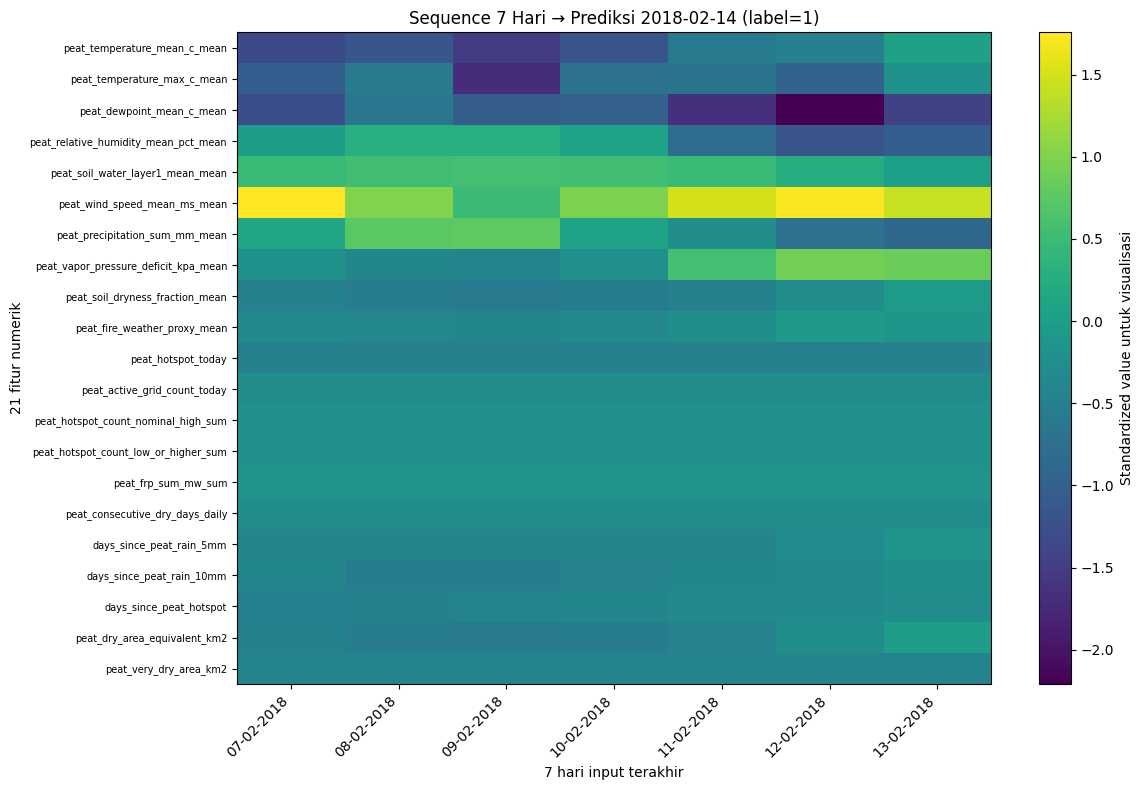

Saved: /content/drive/MyDrive/gemastik/data/model/gru_gemastik_2026_full_recall_optimized/figures/sequence_7day_to_hplus1.png


In [ ]:
# Heatmap untuk merepresentasikan 21 numeric features × 7 hari.
dev_mean = development[FINAL_FEATURES].mean()
dev_std = development[FINAL_FEATURES].std().replace(0, 1)

visual_matrix = (
    (example_window[FINAL_FEATURES] - dev_mean) / dev_std
).T

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(
    visual_matrix.to_numpy(),
    aspect="auto",
)

ax.set_xticks(range(FINAL_WINDOW))
ax.set_xticklabels(
    [
        pd.Timestamp(d).strftime("%d-%m-%Y")
        for d in example_window["date"]
    ],
    rotation=45,
    ha="right",
)

ax.set_yticks(range(len(FINAL_FEATURES)))
ax.set_yticklabels(FINAL_FEATURES, fontsize=7)

ax.set_xlabel("7 hari input terakhir")
ax.set_ylabel("21 fitur numerik")
ax.set_title(
    f"Sequence 7 Hari → Prediksi {target_date_example.date()} "
    f"(label={target_label_example})"
)

fig.colorbar(
    im,
    ax=ax,
    label="Standardized value untuk visualisasi",
)

fig.tight_layout()

sequence_fig = FIGURE_DIR / "sequence_7day_to_hplus1.png"
fig.savefig(
    sequence_fig,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print("Saved:", sequence_fig)

# BAGIAN D — EKSPERIMEN ARSITEKTUR DAN OPTIMASI RECALL

## 16. Tabel perbandingan GRU vs BiGRU

Tabel ini adalah dokumentasi hasil eksperimen arsitektur pada walk-forward 2020–2023.  
BiGRU64 memiliki accuracy raw tertinggi pada tahap ini dan dijadikan anchor optimasi recall.

In [ ]:
architecture_comparison = pd.DataFrame([
    [1, "BiGRU", 64, 16, 0.20, 0.001, 7, "class_year_recency", 0.8513, 0.2687, 0.3066, 0.6067],
    [2, "GRU",   32, 16, 0.20, 0.001, 7, "class_year_recency", 0.8420, 0.3159, 0.2725, 0.5973],
    [3, "GRU",   64, 16, 0.20, 0.001, 7, "class_year_recency", 0.8417, 0.3007, 0.2407, 0.5841],
    [4, "BiGRU", 32, 16, 0.20, 0.001, 7, "class_year_recency", 0.8332, 0.2169, 0.3541, 0.6095],
    [5, "GRU",  128, 16, 0.20, 0.001, 7, "class_year_recency", 0.8267, 0.3100, 0.2651, 0.5870],
    [6, "GRU",    8, 16, 0.20, 0.001, 7, "class_year_recency", 0.8237, 0.2931, 0.2793, 0.5880],
    [7, "BiGRU",  8, 16, 0.20, 0.001, 7, "class_year_recency", 0.8114, 0.2022, 0.3735, 0.6021],
    [8, "BiGRU",128, 16, 0.20, 0.001, 7, "class_year_recency", 0.8040, 0.2553, 0.3224, 0.5878],
    [9, "GRU",   16, 16, 0.20, 0.001, 7, "class_year_recency", 0.8009, 0.2051, 0.3876, 0.6002],
    [10,"BiGRU", 16, 16, 0.20, 0.001, 7, "class_year_recency", 0.7987, 0.1779, 0.3539, 0.5830],
], columns=[
    "No",
    "Architecture",
    "GRU Units",
    "Dense",
    "Dropout",
    "Learning Rate",
    "Window",
    "Weighting",
    "Accuracy",
    "Precision",
    "Recall",
    "Balanced Accuracy",
])

display(
    architecture_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "Balanced Accuracy": "{:.2%}",
    })
)

architecture_comparison.to_csv(
    REPORT_DIR / "architecture_comparison.csv",
    index=False,
)

,No,Architecture,GRU Units,Dense,Dropout,Learning Rate,Window,Weighting,Accuracy,Precision,Recall,Balanced Accuracy
0,1,BiGRU,64,16,0.200000,0.001000,7,class_year_recency,85.13%,26.87%,30.66%,60.67%
1,2,GRU,32,16,0.200000,0.001000,7,class_year_recency,84.20%,31.59%,27.25%,59.73%
2,3,GRU,64,16,0.200000,0.001000,7,class_year_recency,84.17%,30.07%,24.07%,58.41%
3,4,BiGRU,32,16,0.200000,0.001000,7,class_year_recency,83.32%,21.69%,35.41%,60.95%
4,5,GRU,128,16,0.200000,0.001000,7,class_year_recency,82.67%,31.00%,26.51%,58.70%
5,6,GRU,8,16,0.200000,0.001000,7,class_year_recency,82.37%,29.31%,27.93%,58.80%
6,7,BiGRU,8,16,0.200000,0.001000,7,class_year_recency,81.14%,20.22%,37.35%,60.21%
7,8,BiGRU,128,16,0.200000,0.001000,7,class_year_recency,80.40%,25.53%,32.24%,58.78%
8,9,GRU,16,16,0.200000,0.001000,7,class_year_recency,80.09%,20.51%,38.76%,60.02%
9,10,BiGRU,16,16,0.200000,0.001000,7,class_year_recency,79.87%,17.79%,35.39%,58.30%


## 17. Tahapan optimasi recall BiGRU64

In [ ]:
recall_optimization_history = pd.DataFrame([
    ["Baseline", "BiGRU", 64, "class_year_recency", "BCE", np.nan, 0.00100, np.nan, 0.8513, 0.2687, 0.3066, 0.6067],
    ["Phase 4A", "BiGRU", 64, "class_year_recency", "BCE", np.nan, 0.00100, 0.290, 0.8507, 0.2526, 0.3243, 0.6055],
    ["Phase 4B-1", "BiGRU", 64, "class_year_recency + positive boost 1.75", "BCE", np.nan, 0.00100, 0.290, 0.8437, 0.2699, 0.3360, 0.6082],
    ["Phase 4B-2", "BiGRU", 64, "class_year_balanced", "BCE", np.nan, 0.00100, 0.290, 0.8565, 0.2581, 0.3254, 0.6102],
    ["Phase 4C", "BiGRU", 64, "class_year_balanced", "Focal", 3.0, 0.00100, 0.290, 0.8587, 0.2859, 0.3443, 0.6210],
    ["Phase 4D", "BiGRU", 64, "class_year_balanced", "Focal", 3.0, 0.00100, 0.295, 0.8555, 0.2940, 0.3489, 0.6212],
    ["Phase 4E", "BiGRU", 64, "class_year_balanced", "Focal", 4.0, 0.00100, 0.280, 0.8638, 0.3158, 0.3600, 0.6322],
    ["Phase 4F-1 / Recall Optimized", "BiGRU", 64, "class_year_balanced", "Focal", 4.0, 0.00075, 0.295, 0.8503, 0.3114, 0.3761, 0.6300],
], columns=[
    "Stage",
    "Architecture",
    "Units",
    "Weighting",
    "Loss",
    "Gamma",
    "Learning Rate",
    "Alarm Fraction",
    "Accuracy",
    "Precision",
    "Recall",
    "Balanced Accuracy",
])

display(
    recall_optimization_history.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "Balanced Accuracy": "{:.2%}",
    }, na_rep="-")
)

recall_optimization_history.to_csv(
    REPORT_DIR / "recall_optimization_history.csv",
    index=False,
)

print(
    "Recall improvement:",
    f"{(0.3761 - 0.3066) * 100:.2f} percentage points",
)
print(
    "Accuracy change:",
    f"{(0.8503 - 0.8513) * 100:.2f} percentage points",
)

,Stage,Architecture,Units,Weighting,Loss,Gamma,Learning Rate,Alarm Fraction,Accuracy,Precision,Recall,Balanced Accuracy
0,Baseline,BiGRU,64,class_year_recency,BCE,-,0.001000,-,85.13%,26.87%,30.66%,60.67%
1,Phase 4A,BiGRU,64,class_year_recency,BCE,-,0.001000,0.290000,85.07%,25.26%,32.43%,60.55%
2,Phase 4B-1,BiGRU,64,class_year_recency + positive boost 1.75,BCE,-,0.001000,0.290000,84.37%,26.99%,33.60%,60.82%
3,Phase 4B-2,BiGRU,64,class_year_balanced,BCE,-,0.001000,0.290000,85.65%,25.81%,32.54%,61.02%
4,Phase 4C,BiGRU,64,class_year_balanced,Focal,3.000000,0.001000,0.290000,85.87%,28.59%,34.43%,62.10%
5,Phase 4D,BiGRU,64,class_year_balanced,Focal,3.000000,0.001000,0.295000,85.55%,29.40%,34.89%,62.12%
6,Phase 4E,BiGRU,64,class_year_balanced,Focal,4.000000,0.001000,0.280000,86.38%,31.58%,36.00%,63.22%
7,Phase 4F-1 / Recall Optimized,BiGRU,64,class_year_balanced,Focal,4.000000,0.000750,0.295000,85.03%,31.14%,37.61%,63.00%


Recall improvement: 6.95 percentage points
Accuracy change: -0.10 percentage points


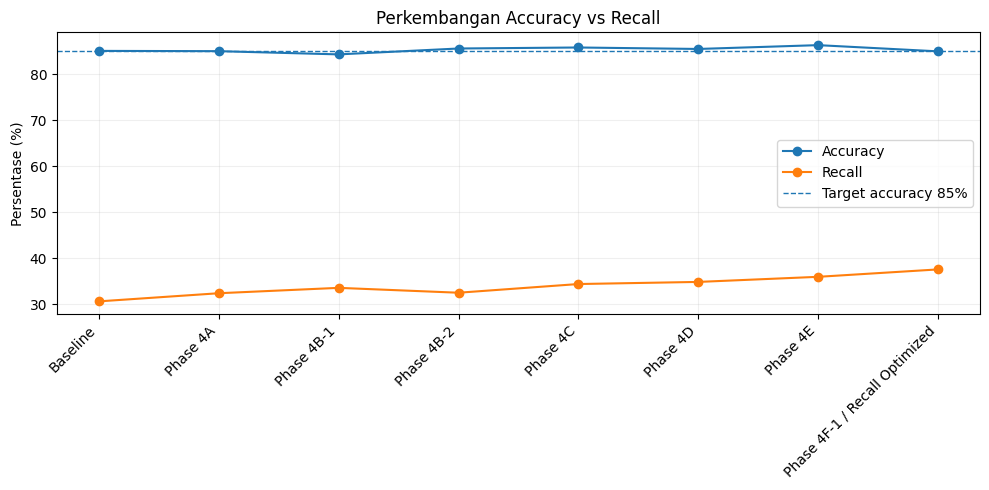

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(recall_optimization_history))

ax.plot(
    x,
    recall_optimization_history["Accuracy"] * 100,
    marker="o",
    label="Accuracy",
)

ax.plot(
    x,
    recall_optimization_history["Recall"] * 100,
    marker="o",
    label="Recall",
)

ax.set_xticks(x)
ax.set_xticklabels(
    recall_optimization_history["Stage"],
    rotation=45,
    ha="right",
)

ax.axhline(85, linestyle="--", linewidth=1, label="Target accuracy 85%")
ax.set_ylabel("Persentase (%)")
ax.set_title("Perkembangan Accuracy vs Recall")
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "optimization_accuracy_recall.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

# BAGIAN E — FINAL MODEL REPRODUCTION

## 18. Freeze konfigurasi final

In [ ]:
FINAL_CONFIG = {
    "architecture": "bigru",
    "gru_units": 64,
    "dense_units": 16,
    "dropout_rate": 0.20,
    "learning_rate": 7.5e-4,
    "weighting_mode": "class_year_balanced",
    "loss": "binary_focal_crossentropy",
    "focal_gamma": 4.0,
    "window": 7,
    "alarm_fraction": 0.295,
}

FINAL_ALARM_FRACTION = float(
    FINAL_CONFIG["alarm_fraction"]
)

BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 10
MAX_SAMPLE_WEIGHT = 8.0
GRADIENT_CLIPNORM = 1.0

display(
    pd.Series(
        FINAL_CONFIG,
        name="value",
    ).to_frame()
)

,value
architecture,bigru
gru_units,64
dense_units,16
dropout_rate,0.2
learning_rate,0.00075
weighting_mode,class_year_balanced
loss,binary_focal_crossentropy
focal_gamma,4.0
window,7
alarm_fraction,0.295


## 19. Utility metrics

In [ ]:
def safe_roc_auc(y_true, score):
    y_true = np.asarray(y_true, dtype=np.int8)
    score = np.asarray(score, dtype=float)

    if np.unique(y_true).size < 2:
        return float("nan")

    return float(
        roc_auc_score(
            y_true,
            score,
        )
    )


def ranking_metrics(y_true, score):
    y_true = np.asarray(y_true, dtype=np.int8)
    score = np.asarray(score, dtype=float)

    return {
        "n": int(len(y_true)),
        "positive": int(y_true.sum()),
        "prevalence": float(y_true.mean()),
        "pr_auc": float(
            average_precision_score(
                y_true,
                score,
            )
        ),
        "roc_auc": safe_roc_auc(
            y_true,
            score,
        ),
    }


def classification_metrics(
    y_true,
    score,
    threshold,
):
    y_true = np.asarray(y_true, dtype=np.int8)
    score = np.clip(
        np.asarray(score, dtype=float),
        1e-8,
        1 - 1e-8,
    )

    pred = (
        score >= float(threshold)
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1],
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp)
        else np.nan
    )

    fpr = (
        fp / (tn + fp)
        if (tn + fp)
        else np.nan
    )

    accuracy = float(
        accuracy_score(
            y_true,
            pred,
        )
    )

    always_zero_accuracy = float(
        (y_true == 0).mean()
    )

    return {
        "accuracy": accuracy,
        "always_zero_accuracy": always_zero_accuracy,
        "accuracy_lift_vs_zero": accuracy - always_zero_accuracy,
        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                pred,
            )
        ),
        "precision": float(
            precision_score(
                y_true,
                pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                pred,
                zero_division=0,
            )
        ),
        "specificity": float(specificity),
        "false_positive_rate": float(fpr),
        "predicted_positive_rate": float(pred.mean()),
        "f1": float(
            f1_score(
                y_true,
                pred,
                zero_division=0,
            )
        ),
        "f2": float(
            fbeta_score(
                y_true,
                pred,
                beta=2,
                zero_division=0,
            )
        ),
        "mcc": float(
            matthews_corrcoef(
                y_true,
                pred,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                y_true,
                score,
            )
        ),
        "roc_auc": safe_roc_auc(
            y_true,
            score,
        ),
        "brier_score": float(
            brier_score_loss(
                y_true,
                score,
            )
        ),
        "log_loss": float(
            log_loss(
                y_true,
                score,
                labels=[0, 1],
            )
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

## 20. Preprocessor dan class-year-balanced weighting

In [ ]:
def make_preprocessor():
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
            ),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ])


def class_weights(y):
    y = np.asarray(
        y,
        dtype=np.int8,
    )

    counts = np.bincount(
        y,
        minlength=2,
    ).astype(float)

    if np.any(counts == 0):
        raise RuntimeError(
            "Kedua kelas dibutuhkan untuk weighting."
        )

    n = counts.sum()

    mapping = {
        0: n / (2 * counts[0]),
        1: n / (2 * counts[1]),
    }

    w = np.asarray(
        [
            mapping[int(v)]
            for v in y
        ],
        dtype=float,
    )

    return (
        w / w.mean()
    ).astype("float32")


def class_year_weights(
    y,
    years,
):
    y = np.asarray(
        y,
        dtype=np.int8,
    )

    years = np.asarray(
        years,
        dtype=int,
    )

    base = class_weights(
        y
    ).astype(float)

    vc = pd.Series(
        years
    ).value_counts()

    year_factor = np.asarray(
        [
            len(years)
            / (
                len(vc)
                * vc[int(year)]
            )
            for year in years
        ],
        dtype=float,
    )

    w = base * year_factor
    w /= w.mean()

    w = np.clip(
        w,
        1 / MAX_SAMPLE_WEIGHT,
        MAX_SAMPLE_WEIGHT,
    )

    return (
        w / w.mean()
    ).astype("float32")

## 21. Build final BiGRU64 + Focal Loss γ=4

In [ ]:
def build_final_model(
    window,
    n_features,
    seed,
):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(
        int(seed)
    )

    inp = tf.keras.Input(
        shape=(
            int(window),
            int(n_features),
        ),
        name="sequence_input",
    )

    gru_core = tf.keras.layers.GRU(
        int(
            FINAL_CONFIG[
                "gru_units"
            ]
        ),
        name="gru_core",
    )

    x = tf.keras.layers.Bidirectional(
        gru_core,
        name="bidirectional_gru",
    )(inp)

    x = tf.keras.layers.Dropout(
        float(
            FINAL_CONFIG[
                "dropout_rate"
            ]
        ),
        seed=int(seed),
        name="dropout_1",
    )(x)

    x = tf.keras.layers.Dense(
        int(
            FINAL_CONFIG[
                "dense_units"
            ]
        ),
        activation="relu",
        name="dense_relu",
    )(x)

    x = tf.keras.layers.Dropout(
        float(
            FINAL_CONFIG[
                "dropout_rate"
            ]
        ),
        seed=int(seed) + 1,
        name="dropout_2",
    )(x)

    out = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="risk_score",
    )(x)

    model = tf.keras.Model(
        inp,
        out,
        name="bigru64_recall_optimized",
    )

    focal_loss = (
        tf.keras.losses.BinaryFocalCrossentropy(
            gamma=float(
                FINAL_CONFIG[
                    "focal_gamma"
                ]
            ),
            apply_class_balancing=False,
            from_logits=False,
        )
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=float(
                FINAL_CONFIG[
                    "learning_rate"
                ]
            ),
            clipnorm=GRADIENT_CLIPNORM,
        ),
        loss=focal_loss,
    )

    return model


demo_model = build_final_model(
    FINAL_WINDOW,
    len(FINAL_FEATURES) + 1,
    SEEDS[0],
)

demo_model.summary()

del demo_model
tf.keras.backend.clear_session()

Model: "bigru64_recall_optimized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequence_input (InputLayer)     │ (None, 7, 22)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_gru               │ (None, 128)            │        33,792 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_relu (Dense)              │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ risk_score (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,873 (140.13 KB)

 Trainable params: 35,873 (140.13 KB)

 Non-trainable params: 0 (0.00 B)

## 22. Sequence builder

In [ ]:
def create_sequences(
    frame,
    transformed_matrix,
    sample_mask,
    window,
):
    X = []
    y = []
    meta = []

    sample_positions = np.flatnonzero(
        np.asarray(
            sample_mask,
            dtype=bool,
        )
    )

    for end_pos in sample_positions:
        start_pos = (
            int(end_pos)
            - int(window)
            + 1
        )

        if start_pos < 0:
            continue

        sequence_frame = frame.iloc[
            start_pos:end_pos + 1
        ]

        if len(sequence_frame) != window:
            continue

        if not (
            sequence_frame["date"]
            .diff()
            .dropna()
            .eq(
                pd.Timedelta(days=1)
            )
            .all()
        ):
            raise RuntimeError(
                "Sequence tidak consecutive."
            )

        target_value = (
            frame.iloc[end_pos][TARGET]
        )

        if pd.isna(target_value):
            continue

        X.append(
            transformed_matrix[
                start_pos:end_pos + 1
            ]
        )

        y.append(
            int(target_value)
        )

        meta.append({
            "date": frame.iloc[end_pos]["date"],
            "target_date": frame.iloc[end_pos]["target_date"],
            "target_year": int(frame.iloc[end_pos]["target_year"]),
            "missing_history_days": int(
                sequence_frame[
                    "calendar_observed"
                ].eq(0).sum()
            ),
        })

    if not X:
        raise RuntimeError(
            "Tidak ada sequence yang terbentuk."
        )

    return (
        np.stack(X).astype("float32"),
        np.asarray(
            y,
            dtype=np.int8,
        ),
        pd.DataFrame(meta),
    )

## 23. Walk-forward fold tanpa leakage

In [ ]:
FOLD_CACHE = {}


def get_final_fold(
    validation_year,
):
    validation_year = int(
        validation_year
    )

    cache_key = (
        validation_year,
        FINAL_WINDOW,
    )

    if cache_key in FOLD_CACHE:
        return FOLD_CACHE[
            cache_key
        ]

    train_mask = (
        optimization_frame[TARGET].notna()
        & optimization_frame["target_year"].lt(
            validation_year
        )
    )

    validation_mask = (
        optimization_frame[TARGET].notna()
        & optimization_frame["target_year"].eq(
            validation_year
        )
    )

    last_train_date = (
        optimization_frame.loc[
            train_mask,
            "date",
        ].max()
    )

    # Fit numeric preprocessor only sampai training cutoff.
    fit_rows = (
        optimization_frame[
            "calendar_observed"
        ].eq(1)
        & optimization_frame["date"].le(
            last_train_date
        )
    )

    preprocessor = (
        make_preprocessor()
    )

    preprocessor.fit(
        optimization_frame.loc[
            fit_rows,
            FINAL_FEATURES,
        ]
    )

    transformed_numeric = (
        preprocessor.transform(
            optimization_frame[
                FINAL_FEATURES
            ]
        )
        .astype("float32")
    )

    transformed_all = np.c_[
        transformed_numeric,
        optimization_frame[
            "calendar_observed"
        ].to_numpy(
            dtype="float32"
        ),
    ]

    X_train, y_train, meta_train = (
        create_sequences(
            optimization_frame,
            transformed_all,
            train_mask,
            FINAL_WINDOW,
        )
    )

    X_val, y_val, meta_val = (
        create_sequences(
            optimization_frame,
            transformed_all,
            validation_mask,
            FINAL_WINDOW,
        )
    )

    if len(X_val) != int(
        validation_mask.sum()
    ):
        raise RuntimeError(
            f"Validation coverage {validation_year} "
            f"tidak 100%: {len(X_val)} "
            f"vs {int(validation_mask.sum())}"
        )

    result = {
        "preprocessor": preprocessor,
        "X_train": X_train,
        "y_train": y_train,
        "meta_train": meta_train,
        "X_val": X_val,
        "y_val": y_val,
        "meta_val": meta_val,
    }

    FOLD_CACHE[
        cache_key
    ] = result

    return result


def inner_temporal_split(
    X,
    y,
    meta,
):
    for fraction in [
        0.15,
        0.20,
        0.25,
        0.10,
    ]:
        split_idx = min(
            max(
                int(
                    len(X)
                    * (1 - fraction)
                ),
                50,
            ),
            len(X) - 30,
        )

        if (
            np.unique(
                y[:split_idx]
            ).size == 2
            and
            np.unique(
                y[split_idx:]
            ).size == 2
        ):
            return (
                X[:split_idx],
                y[:split_idx],
                meta.iloc[
                    :split_idx
                ].reset_index(
                    drop=True
                ),
                X[split_idx:],
                y[split_idx:],
                meta.iloc[
                    split_idx:
                ].reset_index(
                    drop=True
                ),
            )

    raise RuntimeError(
        "Inner temporal split gagal."
    )

## 24. Reproduce konfigurasi final pada walk-forward 2020–2023

Tidak ada hyperparameter search lagi pada bagian ini.  
Yang dijalankan hanya konfigurasi final yang sudah dibekukan.

In [ ]:
def train_final_fold(
    validation_year,
    seed,
):
    fold = get_final_fold(
        validation_year
    )

    X_train = fold["X_train"]
    y_train = fold["y_train"]
    meta_train = fold[
        "meta_train"
    ]

    X_val = fold["X_val"]
    y_val = fold["y_val"]

    (
        X_fit,
        y_fit,
        meta_fit,
        X_inner,
        y_inner,
        meta_inner,
    ) = inner_temporal_split(
        X_train,
        y_train,
        meta_train,
    )

    sample_weight = (
        class_year_weights(
            y_fit,
            meta_fit[
                "target_year"
            ].to_numpy(),
        )
    )

    model = build_final_model(
        FINAL_WINDOW,
        X_train.shape[-1],
        int(seed)
        + int(validation_year)
        * 100,
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            min_delta=1e-4,
            restore_best_weights=True,
            verbose=0,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-5,
            verbose=0,
        ),
    ]

    start_time = time.perf_counter()

    history = model.fit(
        X_fit,
        y_fit,
        validation_data=(
            X_inner,
            y_inner,
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        sample_weight=sample_weight,
        shuffle=False,
        callbacks=callbacks,
        verbose=0,
    )

    train_score = (
        model.predict(
            X_train,
            batch_size=BATCH_SIZE,
            verbose=0,
        )
        .reshape(-1)
    )

    val_score = (
        model.predict(
            X_val,
            batch_size=BATCH_SIZE,
            verbose=0,
        )
        .reshape(-1)
    )

    # Alarm-fraction policy:
    # threshold dihitung dari TRAIN score, bukan label validation.
    threshold = float(
        np.quantile(
            train_score,
            1.0
            - FINAL_ALARM_FRACTION,
        )
    )

    metrics = (
        classification_metrics(
            y_val,
            val_score,
            threshold,
        )
    )

    best_epoch = int(
        np.argmin(
            history.history[
                "val_loss"
            ]
        )
        + 1
    )

    row = {
        "validation_year": int(
            validation_year
        ),
        "seed": int(seed),
        "best_epoch": best_epoch,
        "threshold": threshold,
        "duration_seconds": float(
            time.perf_counter()
            - start_time
        ),
        **metrics,
    }

    del (
        model,
        history,
        callbacks,
        sample_weight,
    )

    tf.keras.backend.clear_session()
    gc.collect()

    return row

In [ ]:
walk_forward_rows = []

for validation_year in WALK_FORWARD_YEARS:
    for seed in SEEDS:
        result = train_final_fold(
            validation_year,
            seed,
        )

        walk_forward_rows.append(
            result
        )

        print(
            f"year={validation_year} "
            f"seed={seed} | "
            f"acc={result['accuracy']:.4f} | "
            f"precision={result['precision']:.4f} | "
            f"recall={result['recall']:.4f} | "
            f"bal={result['balanced_accuracy']:.4f} | "
            f"PR={result['pr_auc']:.4f}"
        )

walk_forward_raw = pd.DataFrame(
    walk_forward_rows
)

display(walk_forward_raw)

walk_forward_raw.to_csv(
    REPORT_DIR
    / "final_walk_forward_raw.csv",
    index=False,
)

year=2020 seed=42 | acc=0.8607 | precision=0.0000 | recall=0.0000 | bal=0.4758 | PR=0.1020
year=2020 seed=2026 | acc=0.8962 | precision=0.3333 | recall=0.0857 | bal=0.5338 | PR=0.1823
year=2021 seed=42 | acc=0.8548 | precision=0.3958 | recall=0.4419 | bal=0.6759 | PR=0.3873
year=2021 seed=2026 | acc=0.8411 | precision=0.3529 | recall=0.4186 | bal=0.6581 | PR=0.3814
year=2022 seed=42 | acc=0.9083 | precision=0.1000 | recall=0.1250 | bal=0.5355 | PR=0.0632
year=2022 seed=2026 | acc=0.8883 | precision=0.1034 | recall=0.1875 | bal=0.5547 | PR=0.0760
year=2023 seed=42 | acc=0.7616 | precision=0.5848 | recall=0.8621 | bal=0.7885 | PR=0.8747
year=2023 seed=2026 | acc=0.7918 | precision=0.6205 | recall=0.8879 | bal=0.8175 | PR=0.8880


,validation_year,seed,best_epoch,threshold,duration_seconds,accuracy,always_zero_accuracy,accuracy_lift_vs_zero,balanced_accuracy,precision,...,f2,mcc,pr_auc,roc_auc,brier_score,log_loss,tn,fp,fn,tp
0,2020,42,3,0.535799,10.296642,0.860656,0.904372,-0.043716,0.475831,0.000000,...,0.000000,-0.069526,0.101953,0.528097,0.185702,0.561177,315,16,35,0
1,2020,2026,6,0.529317,10.951292,0.896175,0.904372,-0.008197,0.533794,0.333333,...,0.100671,0.128339,0.182258,0.578334,0.200066,0.591915,325,6,32,3
2,2021,42,15,0.482730,17.475018,0.854795,0.882192,-0.027397,0.675899,0.395833,...,0.431818,0.335587,0.387255,0.720786,0.180146,0.547822,293,29,24,19
3,2021,2026,17,0.488050,18.964352,0.841096,0.882192,-0.041096,0.658060,0.352941,...,0.403587,0.293944,0.381387,0.714213,0.187531,0.564357,289,33,25,18
4,2022,42,11,0.481685,20.568566,0.908309,0.954155,-0.045845,0.535473,0.100000,...,0.119048,0.063841,0.063244,0.526464,0.186757,0.564245,315,18,14,2
5,2022,2026,2,0.483104,13.609366,0.888252,0.954155,-0.065903,0.554711,0.103448,...,0.161290,0.082911,0.076038,0.535473,0.185280,0.561761,307,26,13,3
6,2023,42,10,0.463850,19.639103,0.761644,0.682192,0.079452,0.788464,0.584795,...,0.787402,0.538334,0.874703,0.897833,0.187362,0.563961,178,71,16,100
7,2023,2026,10,0.476370,15.090011,0.791781,0.682192,0.109589,0.817459,0.620482,...,0.817460,0.593699,0.887991,0.915732,0.192930,0.574465,186,63,13,103


## 25. Agregasi seed → per tahun → overall

In [ ]:
final_yearly = (
    walk_forward_raw
    .groupby(
        "validation_year",
        as_index=False,
    )
    .agg(
        accuracy=("accuracy", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        f1=("f1", "mean"),
        f2=("f2", "mean"),
        mcc=("mcc", "mean"),
        pr_auc=("pr_auc", "mean"),
        roc_auc=("roc_auc", "mean"),
        false_positive_rate=("false_positive_rate", "mean"),
        predicted_positive_rate=("predicted_positive_rate", "mean"),
        always_zero_accuracy=("always_zero_accuracy", "mean"),
        accuracy_lift_vs_zero=("accuracy_lift_vs_zero", "mean"),
        best_epoch_median=("best_epoch", "median"),
    )
)

final_summary = pd.DataFrame([
    {
        "mean_accuracy": final_yearly["accuracy"].mean(),
        "mean_precision": final_yearly["precision"].mean(),
        "mean_recall": final_yearly["recall"].mean(),
        "min_year_recall": final_yearly["recall"].min(),
        "mean_balanced_accuracy": final_yearly["balanced_accuracy"].mean(),
        "mean_f1": final_yearly["f1"].mean(),
        "mean_f2": final_yearly["f2"].mean(),
        "mean_mcc": final_yearly["mcc"].mean(),
        "mean_pr_auc": final_yearly["pr_auc"].mean(),
        "mean_roc_auc": final_yearly["roc_auc"].mean(),
        "mean_fpr": final_yearly["false_positive_rate"].mean(),
        "mean_accuracy_lift_vs_zero": final_yearly["accuracy_lift_vs_zero"].mean(),
    }
])

print("PER VALIDATION YEAR")
display(
    final_yearly.style.format({
        "accuracy": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "balanced_accuracy": "{:.2%}",
        "f1": "{:.2%}",
        "f2": "{:.2%}",
        "pr_auc": "{:.4f}",
        "roc_auc": "{:.4f}",
        "false_positive_rate": "{:.2%}",
        "predicted_positive_rate": "{:.2%}",
        "always_zero_accuracy": "{:.2%}",
        "accuracy_lift_vs_zero": "{:+.2%}",
    })
)

print("OVERALL")
display(
    final_summary.style.format({
        "mean_accuracy": "{:.2%}",
        "mean_precision": "{:.2%}",
        "mean_recall": "{:.2%}",
        "min_year_recall": "{:.2%}",
        "mean_balanced_accuracy": "{:.2%}",
        "mean_f1": "{:.2%}",
        "mean_f2": "{:.2%}",
        "mean_pr_auc": "{:.4f}",
        "mean_roc_auc": "{:.4f}",
        "mean_fpr": "{:.2%}",
        "mean_accuracy_lift_vs_zero": "{:+.2%}",
    })
)

final_yearly.to_csv(
    REPORT_DIR
    / "final_walk_forward_yearly.csv",
    index=False,
)

final_summary.to_csv(
    REPORT_DIR
    / "final_walk_forward_summary.csv",
    index=False,
)

PER VALIDATION YEAR


,validation_year,accuracy,precision,recall,balanced_accuracy,f1,f2,mcc,pr_auc,roc_auc,false_positive_rate,predicted_positive_rate,always_zero_accuracy,accuracy_lift_vs_zero,best_epoch_median
0,2020,87.84%,16.67%,4.29%,50.48%,6.82%,5.03%,0.029407,0.1421,0.5532,3.32%,3.42%,90.44%,-2.60%,4.500000
1,2021,84.79%,37.44%,43.02%,66.70%,40.03%,41.77%,0.314766,0.3843,0.7175,9.63%,13.56%,88.22%,-3.42%,16.000000
2,2022,89.83%,10.17%,15.62%,54.51%,12.22%,14.02%,0.073376,0.0696,0.5310,6.61%,7.02%,95.42%,-5.59%,6.500000
3,2023,77.67%,60.26%,87.50%,80.30%,71.37%,80.24%,0.566016,0.8813,0.9068,26.91%,46.16%,68.22%,+9.45%,10.000000


OVERALL


,mean_accuracy,mean_precision,mean_recall,min_year_recall,mean_balanced_accuracy,mean_f1,mean_f2,mean_mcc,mean_pr_auc,mean_roc_auc,mean_fpr,mean_accuracy_lift_vs_zero
0,85.03%,31.14%,37.61%,4.29%,63.00%,32.61%,35.27%,0.245891,0.3694,0.6771,11.62%,-0.54%


### Benchmark pembanding dari eksperimen Phase 4F-1

Notebook eksperimen sebelumnya menghasilkan sekitar:

- Accuracy: **85.03%**
- Precision: **31.14%**
- Recall: **37.61%**
- Balanced Accuracy: **63.00%**
- PR-AUC: **0.3694**

Perbedaan kecil dapat muncul bila versi TensorFlow/hardware berbeda, tetapi konfigurasi dan prosedur temporal tidak boleh diubah hanya untuk mengejar angka.

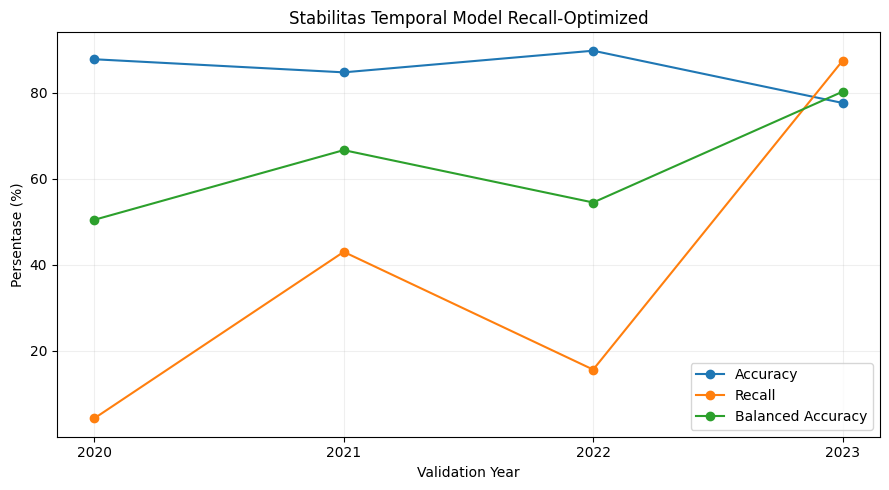

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    final_yearly["validation_year"],
    final_yearly["accuracy"] * 100,
    marker="o",
    label="Accuracy",
)

ax.plot(
    final_yearly["validation_year"],
    final_yearly["recall"] * 100,
    marker="o",
    label="Recall",
)

ax.plot(
    final_yearly["validation_year"],
    final_yearly["balanced_accuracy"] * 100,
    marker="o",
    label="Balanced Accuracy",
)

ax.set_xticks(WALK_FORWARD_YEARS)
ax.set_xlabel("Validation Year")
ax.set_ylabel("Persentase (%)")
ax.set_title("Stabilitas Temporal Model Recall-Optimized")
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "final_temporal_stability.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()

# BAGIAN F — TRAINING MODEL FINAL

## 26. Pilih epoch final hanya dari development

Agar tidak mengarang jumlah epoch, notebook mengambil median `best_epoch` dari seluruh fold/seed final.  
Tidak ada informasi 2024–2025 yang digunakan.

In [ ]:
FINAL_EPOCHS = int(
    max(
        1,
        round(
            float(
                walk_forward_raw[
                    "best_epoch"
                ].median()
            )
        ),
    )
)

FINAL_SEED = 42

print("Final epochs from development:", FINAL_EPOCHS)
print("Final seed:", FINAL_SEED)

Final epochs from development: 10
Final seed: 42


## 27. Fit final preprocessor pada development 2018–2023

In [ ]:
dev_mask = (
    daily_all[TARGET].notna()
    & daily_all["target_year"].le(2023)
)

last_dev_feature_date = (
    daily_all.loc[
        dev_mask,
        "date",
    ].max()
)

final_fit_rows = (
    daily_all[
        "calendar_observed"
    ].eq(1)
    & daily_all["date"].le(
        last_dev_feature_date
    )
)

final_preprocessor = (
    make_preprocessor()
)

final_preprocessor.fit(
    daily_all.loc[
        final_fit_rows,
        FINAL_FEATURES,
    ]
)

final_numeric_all = (
    final_preprocessor.transform(
        daily_all[
            FINAL_FEATURES
        ]
    )
    .astype("float32")
)

# calendar_observed ditambahkan setelah scaler dan tidak distandardisasi.
final_matrix = np.c_[
    final_numeric_all,
    daily_all[
        "calendar_observed"
    ].to_numpy(
        dtype="float32"
    ),
]

print("Final transformed matrix:", final_matrix.shape)
print("Expected channels:", len(FINAL_FEATURES) + 1)

Final transformed matrix: (2892, 22)
Expected channels: 22


## 28. Bentuk seluruh sequence development dan train model final

In [ ]:
X_dev, y_dev, meta_dev = (
    create_sequences(
        daily_all,
        final_matrix,
        dev_mask,
        FINAL_WINDOW,
    )
)

final_sample_weight = (
    class_year_weights(
        y_dev,
        meta_dev[
            "target_year"
        ].to_numpy(),
    )
)

final_model = build_final_model(
    FINAL_WINDOW,
    X_dev.shape[-1],
    FINAL_SEED + 99999,
)

print("X_dev:", X_dev.shape)
print("y_dev:", y_dev.shape)
print("Final epochs:", FINAL_EPOCHS)

final_history = final_model.fit(
    X_dev,
    y_dev,
    epochs=FINAL_EPOCHS,
    batch_size=BATCH_SIZE,
    sample_weight=final_sample_weight,
    shuffle=False,
    verbose=1,
)

X_dev: (2139, 7, 22)
y_dev: (2139,)
Final epochs: 10
Epoch 1/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0436
Epoch 2/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0330
Epoch 3/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0309
Epoch 4/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0313
Epoch 5/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0301
Epoch 6/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0294
Epoch 7/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0294
Epoch 8/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0295
Epoch 9/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0290
Epoch 10/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0280


## 29. Freeze numeric deployment threshold dari development score

In [ ]:
dev_risk_score = (
    final_model.predict(
        X_dev,
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    .reshape(-1)
)

FINAL_THRESHOLD = float(
    np.quantile(
        dev_risk_score,
        1.0
        - FINAL_ALARM_FRACTION,
    )
)

print("Final alarm fraction:", FINAL_ALARM_FRACTION)
print("Final numeric threshold:", FINAL_THRESHOLD)
print("Risk score bukan calibrated probability.")

Final alarm fraction: 0.295
Final numeric threshold: 0.4704242944717407
Risk score bukan calibrated probability.


## 30. Simpan model, preprocessor, configuration manifest

In [ ]:
FINAL_MODEL_PATH = (
    MODEL_DIR
    / "bigru64_focal_g4_lr000075_recall_optimized.keras"
)

FINAL_PREPROCESSOR_PATH = (
    MODEL_DIR
    / "bigru64_recall_optimized_preprocessor.joblib"
)

FINAL_CONFIG_PATH = (
    MODEL_DIR
    / "bigru64_recall_optimized_manifest.json"
)

final_model.save(
    FINAL_MODEL_PATH
)

joblib.dump(
    final_preprocessor,
    FINAL_PREPROCESSOR_PATH,
)

final_manifest = {
    "project": "SIGAP-GAMBUT GEMASTIK XIX 2026",
    "target": TARGET,
    "target_scope": "daily peat area status OKI H+1",
    "features": FINAL_FEATURES,
    "n_numeric_features": len(FINAL_FEATURES),
    "calendar_mask": "calendar_observed",
    "n_input_channels": len(FINAL_FEATURES) + 1,
    "config": FINAL_CONFIG,
    "final_epochs": FINAL_EPOCHS,
    "final_seed": FINAL_SEED,
    "final_threshold": FINAL_THRESHOLD,
    "score_type": "risk_score_not_calibrated_probability",
    "development_years": "2018-2023",
    "walk_forward_years": WALK_FORWARD_YEARS,
    "legacy_holdout_years": TEST_YEARS,
    "legacy_holdout_used_for_new_selection": False,
}

with open(
    FINAL_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_manifest,
        f,
        indent=2,
        default=float,
    )

print("✅ Model:", FINAL_MODEL_PATH)
print("✅ Preprocessor:", FINAL_PREPROCESSOR_PATH)
print("✅ Manifest:", FINAL_CONFIG_PATH)

✅ Model: /content/drive/MyDrive/gemastik/data/model/gru_gemastik_2026_full_recall_optimized/models/bigru64_focal_g4_lr000075_recall_optimized.keras
✅ Preprocessor: /content/drive/MyDrive/gemastik/data/model/gru_gemastik_2026_full_recall_optimized/models/bigru64_recall_optimized_preprocessor.joblib
✅ Manifest: /content/drive/MyDrive/gemastik/data/model/gru_gemastik_2026_full_recall_optimized/models/bigru64_recall_optimized_manifest.json


# BAGIAN G — PREDIKSI DINAMIS

## 31. Prediksi berdasarkan target date

Ini adalah fitur yang ada pada notebook lama dan sekarang dimasukkan kembali.

Untuk target tanggal **D**:
- input date terakhir = **D−1**;
- diambil 7 hari terakhir sampai D−1;
- diproses oleh preprocessor final;
- BiGRU menghasilkan `risk_score`;
- `risk_score >= FINAL_THRESHOLD` → **YA**;
- jika label historis boleh dibuka, prediksi dibandingkan dengan aktual.

### Lock 2024–2025
Secara default `SHOW_LEGACY_LABELS_IN_UI=False`, sehingga tanggal 2024–2025 dapat diprediksi dari fitur yang tersedia tetapi label aktualnya tidak otomatis ditampilkan.

In [ ]:
def parse_target_date(text):
    for date_format in [
        "%Y-%m-%d",
        "%d-%m-%Y",
        "%d/%m/%Y",
    ]:
        try:
            return pd.Timestamp(
                pd.to_datetime(
                    str(text).strip(),
                    format=date_format,
                    errors="raise",
                )
            ).normalize()
        except (
            ValueError,
            TypeError,
        ):
            pass

    raise ValueError(
        "Format tanggal tidak valid. "
        "Gunakan YYYY-MM-DD, DD-MM-YYYY, atau DD/MM/YYYY."
    )


minimum_predictable_target_date = (
    daily_all.iloc[
        FINAL_WINDOW - 1
    ]["date"]
    + pd.Timedelta(days=1)
).normalize()

maximum_predictable_target_date = (
    daily_all["date"].max()
    + pd.Timedelta(days=1)
).normalize()


def predict_sequence_ending_at_position(
    end_pos,
):
    end_pos = int(
        end_pos
    )

    start_pos = (
        end_pos
        - FINAL_WINDOW
        + 1
    )

    if start_pos < 0:
        raise ValueError(
            "Riwayat belum cukup "
            f"untuk sequence {FINAL_WINDOW} hari."
        )

    window = daily_all.iloc[
        start_pos:end_pos + 1
    ].copy()

    if len(window) != FINAL_WINDOW:
        raise RuntimeError(
            "Sequence tidak lengkap."
        )

    if not (
        window["date"]
        .diff()
        .dropna()
        .eq(
            pd.Timedelta(days=1)
        )
        .all()
    ):
        raise RuntimeError(
            "Sequence tidak berturut-turut."
        )

    sequence = final_matrix[
        start_pos:end_pos + 1
    ].astype("float32")

    expected_shape = (
        FINAL_WINDOW,
        len(FINAL_FEATURES) + 1,
    )

    if sequence.shape != expected_shape:
        raise RuntimeError(
            f"Shape sequence salah: "
            f"{sequence.shape} != {expected_shape}"
        )

    risk_score = float(
        final_model.predict(
            sequence[
                None,
                ...
            ],
            verbose=0,
        )
        .reshape(-1)[0]
    )

    prediction = int(
        risk_score
        >= FINAL_THRESHOLD
    )

    missing_history_days = int(
        window[
            "calendar_observed"
        ].eq(0).sum()
    )

    return {
        "history_start": str(
            pd.Timestamp(
                window.iloc[0][
                    "date"
                ]
            ).date()
        ),
        "input_date": str(
            pd.Timestamp(
                window.iloc[-1][
                    "date"
                ]
            ).date()
        ),
        "target_date": str(
            (
                pd.Timestamp(
                    window.iloc[-1][
                        "date"
                    ]
                )
                + pd.Timedelta(days=1)
            ).date()
        ),
        "model": "BiGRU64 Recall Optimized",
        "sequence_length": FINAL_WINDOW,
        "n_input_channels": len(FINAL_FEATURES) + 1,
        "risk_score": risk_score,
        "risk_score_percent": risk_score * 100,
        "alarm_fraction_reference": FINAL_ALARM_FRACTION,
        "threshold": float(FINAL_THRESHOLD),
        "prediction": prediction,
        "prediction_label": (
            "YA"
            if prediction
            else "TIDAK"
        ),
        "missing_history_days": missing_history_days,
        "history_observation_rate": float(
            1
            - missing_history_days
            / FINAL_WINDOW
        ),
    }

In [ ]:
def predict_hotspot_by_date(
    target_date_text,
    verbose=True,
):
    target_date = (
        parse_target_date(
            target_date_text
        )
    )

    if not (
        minimum_predictable_target_date
        <= target_date
        <= maximum_predictable_target_date
    ):
        raise ValueError(
            "Tanggal target harus berada pada rentang "
            f"{minimum_predictable_target_date.date()} "
            "sampai "
            f"{maximum_predictable_target_date.date()} "
            "untuk inference berbasis dataset historis."
        )

    input_date = (
        target_date
        - pd.Timedelta(days=1)
    )

    matches = daily_all.index[
        daily_all[
            "date"
        ].eq(input_date)
    ].tolist()

    if len(matches) != 1:
        raise RuntimeError(
            "Input date tidak unik pada calendar-complete dataset."
        )

    end_pos = int(
        matches[0]
    )

    result = (
        predict_sequence_ending_at_position(
            end_pos
        )
    )

    target_year = int(
        target_date.year
    )

    actual_value = (
        daily_all.iloc[
            end_pos
        ][TARGET]
    )

    legacy_locked = (
        target_year in TEST_YEARS
        and not SHOW_LEGACY_LABELS_IN_UI
    )

    if legacy_locked:
        result.update({
            "actual": None,
            "actual_label": None,
            "verification": (
                "LEGACY LABEL DIKUNCI"
            ),
            "evaluation_type": (
                "legacy-holdout features only"
            ),
        })

    elif pd.notna(
        actual_value
    ):
        actual = int(
            actual_value
        )

        result.update({
            "actual": actual,
            "actual_label": (
                "YA"
                if actual
                else "TIDAK"
            ),
            "verification": (
                "BENAR"
                if actual
                == result[
                    "prediction"
                ]
                else "SALAH"
            ),
            "evaluation_type": (
                "historical labelled"
            ),
        })

    else:
        result.update({
            "actual": None,
            "actual_label": None,
            "verification": (
                "LABEL TIDAK TERSEDIA"
            ),
            "evaluation_type": (
                "unlabelled inference"
            ),
        })

    if verbose:
        print("=" * 82)
        print("PREDIKSI DINAMIS HOTSPOT GAMBUT H+1")
        print("=" * 82)
        print("History            :", result["history_start"], "s.d.", result["input_date"])
        print("Target date        :", result["target_date"])
        print("Model              :", result["model"])
        print("Window             :", result["sequence_length"], "hari")
        print("Input channels     :", result["n_input_channels"])
        print("Risk score         :", f"{result['risk_score']:.6f}")
        print("Catatan            : risk score, bukan calibrated probability")
        print("Alarm fraction     :", f"{FINAL_ALARM_FRACTION:.3f}")
        print("Threshold final    :", f"{FINAL_THRESHOLD:.6f}")
        print("Prediksi           :", result["prediction_label"])
        print(
            "Hari observed      :",
            f"{FINAL_WINDOW-result['missing_history_days']}/{FINAL_WINDOW}",
        )
        print(
            "Aktual             :",
            (
                result["actual_label"]
                if result["actual_label"] is not None
                else "dikunci/tidak tersedia"
            ),
        )
        print("Verifikasi         :", result["verification"])
        print("=" * 82)

    return result


print(
    "Rentang dynamic inference historis:",
    minimum_predictable_target_date.date(),
    "s.d.",
    maximum_predictable_target_date.date(),
)

Rentang dynamic inference historis: 2018-02-06 s.d. 2025-12-31


## 32. Contoh prediksi tanggal historis dan tanggal terakhir dataset

In [ ]:
TARGET_DATE_TO_PREDICT = "2023-09-15"

historical_prediction = (
    predict_hotspot_by_date(
        TARGET_DATE_TO_PREDICT,
        verbose=True,
    )
)

display(
    pd.DataFrame([
        historical_prediction
    ])
)

latest_target_date = (
    maximum_predictable_target_date
)

latest_prediction = (
    predict_hotspot_by_date(
        str(
            latest_target_date.date()
        ),
        verbose=False,
    )
)

print("Prediksi target terakhir yang didukung dataset:")
display(
    pd.DataFrame([
        latest_prediction
    ])
)

PREDIKSI DINAMIS HOTSPOT GAMBUT H+1
History            : 2023-09-08 s.d. 2023-09-14
Target date        : 2023-09-15
Model              : BiGRU64 Recall Optimized
Window             : 7 hari
Input channels     : 22
Risk score         : 0.783759
Catatan            : risk score, bukan calibrated probability
Alarm fraction     : 0.295
Threshold final    : 0.470424
Prediksi           : YA
Hari observed      : 7/7
Aktual             : YA
Verifikasi         : BENAR


,history_start,input_date,target_date,model,sequence_length,n_input_channels,risk_score,risk_score_percent,alarm_fraction_reference,threshold,prediction,prediction_label,missing_history_days,history_observation_rate,actual,actual_label,verification,evaluation_type
0,2023-09-08,2023-09-14,2023-09-15,BiGRU64 Recall Optimized,7,22,0.783759,78.375864,0.295,0.470424,1,YA,0,1.0,1,YA,BENAR,historical labelled


Prediksi target terakhir yang didukung dataset:


,history_start,input_date,target_date,model,sequence_length,n_input_channels,risk_score,risk_score_percent,alarm_fraction_reference,threshold,prediction,prediction_label,missing_history_days,history_observation_rate,actual,actual_label,verification,evaluation_type
0,2025-12-24,2025-12-30,2025-12-31,BiGRU64 Recall Optimized,7,22,0.393373,39.337349,0.295,0.470424,0,TIDAK,0,1.0,None,None,LEGACY LABEL DIKUNCI,legacy-holdout features only


## 33. Future-ready inference dari 7 hari data baru

Fungsi berikut memungkinkan model digunakan untuk tanggal **di luar dataset historis**, asalkan pipeline upstream sudah menyediakan 7 hari fitur final dengan definisi yang sama.

Jadi ini adalah interface inference untuk deployment:

```python
predict_from_external_7day_frame(df_7hari, target_date="2026-...")
```

Notebook **tidak mengunduh ERA5/VIIRS real-time secara otomatis**, karena kode pembentuk semua engineered feature upstream bukan bagian dari notebook modeling ini.

In [ ]:
def predict_from_external_7day_frame(
    history_7d,
    target_date=None,
):
    history_7d = (
        history_7d
        .copy()
        .sort_values("date")
        .reset_index(drop=True)
    )

    required_columns = {
        "date",
        *FINAL_FEATURES,
        "calendar_observed",
    }

    missing = sorted(
        required_columns
        - set(history_7d.columns)
    )

    if missing:
        raise KeyError(
            f"Kolom external history kurang: {missing}"
        )

    if len(history_7d) != FINAL_WINDOW:
        raise ValueError(
            f"Harus tepat {FINAL_WINDOW} hari. "
            f"Diterima {len(history_7d)}."
        )

    history_7d["date"] = (
        pd.to_datetime(
            history_7d["date"]
        )
        .dt.normalize()
    )

    if not (
        history_7d["date"]
        .diff()
        .dropna()
        .eq(
            pd.Timedelta(days=1)
        )
        .all()
    ):
        raise ValueError(
            "External 7-day history harus consecutive."
        )

    numeric = (
        final_preprocessor.transform(
            history_7d[
                FINAL_FEATURES
            ]
        )
        .astype("float32")
    )

    mask = (
        history_7d[
            "calendar_observed"
        ]
        .astype("float32")
        .to_numpy()
    )

    sequence = np.c_[
        numeric,
        mask,
    ][None, ...]

    risk_score = float(
        final_model.predict(
            sequence,
            verbose=0,
        )
        .reshape(-1)[0]
    )

    prediction = int(
        risk_score
        >= FINAL_THRESHOLD
    )

    inferred_target = (
        pd.Timestamp(
            history_7d["date"].iloc[-1]
        )
        + pd.Timedelta(days=1)
    )

    if target_date is not None:
        requested_target = (
            parse_target_date(
                target_date
            )
        )

        if requested_target != inferred_target:
            raise ValueError(
                "target_date harus tepat satu hari setelah "
                "hari terakhir history."
            )

    return {
        "history_start": str(
            history_7d[
                "date"
            ].iloc[0].date()
        ),
        "history_end": str(
            history_7d[
                "date"
            ].iloc[-1].date()
        ),
        "target_date": str(
            inferred_target.date()
        ),
        "risk_score": risk_score,
        "threshold": float(
            FINAL_THRESHOLD
        ),
        "alarm_fraction": float(
            FINAL_ALARM_FRACTION
        ),
        "prediction": prediction,
        "prediction_label": (
            "YA"
            if prediction
            else "TIDAK"
        ),
        "history_observation_rate": float(
            history_7d[
                "calendar_observed"
            ].mean()
        ),
    }

# BAGIAN H — PETA HISTORIS AKTUAL PER GRID

## 34. Peta aktual, bukan spatial forecast

Model BiGRU memprediksi **kejadian harian tingkat wilayah**, bukan koordinat hotspot.

Peta berikut hanya menampilkan **hotspot aktual historis** dari panel grid-hari untuk tanggal target.  
Peta 2024–2025 dikunci secara default agar tidak menjadi jalur tidak langsung untuk melihat label legacy holdout.

In [ ]:
MAP_HISTORY_CACHE = (
    CACHE_DIR
    / "historical_grid_map_cache_recall_optimized.parquet"
)

_map_history = None
_grid_geometry = None


def prepare_map_history():
    global _map_history

    if _map_history is not None:
        return _map_history

    if MAP_HISTORY_CACHE.exists():
        history = pd.read_parquet(
            MAP_HISTORY_CACHE
        )

        history["date"] = (
            pd.to_datetime(
                history["date"],
                errors="raise",
            )
            .dt.normalize()
        )

        _map_history = history
        return _map_history

    if not INPUT_CSV.exists():
        raise FileNotFoundError(
            f"Dataset grid tidak ditemukan: {INPUT_CSV}"
        )

    source_columns = (
        pd.read_csv(
            INPUT_CSV,
            nrows=0,
        )
        .columns
        .tolist()
    )

    peat_area_candidates = [
        "peat_area_km2",
        "peat_explicit_area_km2",
    ]

    peat_flag_candidates = [
        "is_peat",
        "peat_explicit",
        "has_explicit_peat",
    ]

    peat_area_column = next(
        (
            c
            for c in peat_area_candidates
            if c in source_columns
        ),
        None,
    )

    peat_flag_column = next(
        (
            c
            for c in peat_flag_candidates
            if c in source_columns
        ),
        None,
    )

    if (
        peat_area_column is None
        and peat_flag_column is None
    ):
        raise RuntimeError(
            "Kolom penanda gambut eksplisit "
            "tidak ditemukan pada panel."
        )

    peat_column = (
        peat_area_column
        if peat_area_column is not None
        else peat_flag_column
    )

    usecols = [
        "grid_id",
        "date",
        "hotspot_besok",
        peat_column,
    ]

    if "split" in source_columns:
        usecols.append(
            "split"
        )

    frames = []

    for chunk in pd.read_csv(
        INPUT_CSV,
        usecols=usecols,
        chunksize=100_000,
    ):
        chunk["date"] = (
            pd.to_datetime(
                chunk["date"],
                errors="coerce",
            )
            .dt.normalize()
        )

        chunk["grid_id"] = (
            chunk["grid_id"]
            .astype(str)
        )

        chunk["hotspot_besok"] = (
            pd.to_numeric(
                chunk["hotspot_besok"],
                errors="coerce",
            )
            .fillna(0)
            .astype("int8")
        )

        peat_numeric = (
            pd.to_numeric(
                chunk[peat_column],
                errors="coerce",
            )
            .fillna(0)
        )

        chunk["is_explicit_peat"] = (
            peat_numeric > 0
        )

        keep = [
            "grid_id",
            "date",
            "hotspot_besok",
            "is_explicit_peat",
        ]

        if "split" in chunk.columns:
            keep.append(
                "split"
            )

        frames.append(
            chunk[keep]
        )

    history = pd.concat(
        frames,
        ignore_index=True,
    )

    history.to_parquet(
        MAP_HISTORY_CACHE,
        index=False,
    )

    _map_history = history
    return _map_history


def prepare_grid_geometry():
    global _grid_geometry

    if _grid_geometry is not None:
        return _grid_geometry

    try:
        import geopandas as gpd
    except ImportError as exc:
        raise ImportError(
            "Install geopandas terlebih dahulu."
        ) from exc

    grid_file = next(
        (
            p
            for p in GRID_FILE_CANDIDATES
            if p.exists()
        ),
        None,
    )

    if grid_file is None:
        raise FileNotFoundError(
            "grid_oki_10km.geojson tidak ditemukan."
        )

    grid = gpd.read_file(
        grid_file
    )

    if "grid_id" not in grid.columns:
        raise KeyError(
            "grid_id tidak ditemukan pada GeoJSON."
        )

    grid["grid_id"] = (
        grid["grid_id"]
        .astype(str)
    )

    if grid.crs is None:
        raise RuntimeError(
            "CRS grid tidak tersedia."
        )

    grid = grid.to_crs(
        epsg=4326
    )

    _grid_geometry = grid
    return _grid_geometry

In [ ]:
def show_actual_peat_hotspot_map(
    target_date_text,
    save_files=True,
    show_static=True,
):
    try:
        import geopandas as gpd
        import folium
    except ImportError as exc:
        raise ImportError(
            "Peta memerlukan geopandas dan folium."
        ) from exc

    target_date = (
        parse_target_date(
            target_date_text
        )
    )

    if (
        target_date.year in TEST_YEARS
        and not ALLOW_LEGACY_MAP
    ):
        raise ValueError(
            "Peta aktual 2024–2025 dikunci. "
            "Set ALLOW_LEGACY_MAP=True hanya setelah "
            "konfigurasi benar-benar frozen dan Anda menerima "
            "bahwa ini adalah legacy holdout."
        )

    # Pada panel upstream, hotspot_besok pada row date=D-1
    # merepresentasikan actual target D.
    input_date = (
        target_date
        - pd.Timedelta(days=1)
    )

    history = (
        prepare_map_history()
    )

    selected = (
        history.loc[
            history[
                "date"
            ].eq(input_date)
        ]
        .copy()
    )

    if selected.empty:
        raise ValueError(
            f"Data grid untuk target {target_date.date()} "
            "tidak tersedia."
        )

    selected[
        "actual_peat_hotspot"
    ] = (
        selected[
            "is_explicit_peat"
        ]
        & selected[
            "hotspot_besok"
        ].eq(1)
    )

    grid = (
        prepare_grid_geometry()
        .copy()
    )

    map_df = (
        grid.merge(
            selected[
                [
                    "grid_id",
                    "is_explicit_peat",
                    "actual_peat_hotspot",
                ]
            ],
            on="grid_id",
            how="left",
        )
    )

    map_df[
        "is_explicit_peat"
    ] = (
        map_df[
            "is_explicit_peat"
        ]
        .fillna(False)
        .astype(bool)
    )

    map_df[
        "actual_peat_hotspot"
    ] = (
        map_df[
            "actual_peat_hotspot"
        ]
        .fillna(False)
        .astype(bool)
    )

    map_df[
        "status"
    ] = np.where(
        map_df[
            "actual_peat_hotspot"
        ],
        "Ada hotspot pada grid gambut",
        np.where(
            map_df[
                "is_explicit_peat"
            ],
            "Grid gambut tanpa hotspot",
            "Di luar grid gambut eksplisit",
        ),
    )

    center = (
        map_df
        .geometry
        .unary_union
        .centroid
    )

    fmap = folium.Map(
        location=[
            center.y,
            center.x,
        ],
        zoom_start=8,
        tiles="CartoDB positron",
    )

    def style_function(feature):
        status = (
            feature[
                "properties"
            ][
                "status"
            ]
        )

        if status == "Ada hotspot pada grid gambut":
            return {
                "fillColor": "#d73027",
                "color": "#7f0000",
                "weight": 1.0,
                "fillOpacity": 0.75,
            }

        if status == "Grid gambut tanpa hotspot":
            return {
                "fillColor": "#fee08b",
                "color": "#b8860b",
                "weight": 0.7,
                "fillOpacity": 0.40,
            }

        return {
            "fillColor": "#d9d9d9",
            "color": "#969696",
            "weight": 0.4,
            "fillOpacity": 0.15,
        }

    folium.GeoJson(
        map_df[
            [
                "grid_id",
                "status",
                "geometry",
            ]
        ].to_json(),
        style_function=style_function,
        tooltip=folium.GeoJsonTooltip(
            fields=[
                "grid_id",
                "status",
            ],
            aliases=[
                "Grid:",
                "Status:",
            ],
        ),
        name="Hotspot aktual",
    ).add_to(fmap)

    folium.LayerControl().add_to(
        fmap
    )

    safe_date = str(
        target_date.date()
    )

    html_path = (
        MAP_OUTPUT_DIR
        / f"actual_hotspot_{safe_date}.html"
    )

    png_path = (
        MAP_OUTPUT_DIR
        / f"actual_hotspot_{safe_date}.png"
    )

    if save_files:
        fmap.save(
            html_path
        )

    if show_static:
        plot_df = (
            map_df.to_crs(
                epsg=3857
            )
        )

        fig, ax = plt.subplots(
            figsize=(9, 9)
        )

        non_peat = plot_df.loc[
            ~plot_df[
                "is_explicit_peat"
            ]
        ]

        peat_no_hotspot = plot_df.loc[
            plot_df[
                "is_explicit_peat"
            ]
            & ~plot_df[
                "actual_peat_hotspot"
            ]
        ]

        peat_hotspot = plot_df.loc[
            plot_df[
                "actual_peat_hotspot"
            ]
        ]

        if len(non_peat):
            non_peat.plot(
                ax=ax,
                alpha=0.15,
                edgecolor="grey",
            )

        if len(peat_no_hotspot):
            peat_no_hotspot.plot(
                ax=ax,
                alpha=0.40,
                edgecolor="black",
            )

        if len(peat_hotspot):
            peat_hotspot.plot(
                ax=ax,
                alpha=0.85,
                edgecolor="black",
            )

        ax.set_title(
            f"Hotspot Aktual Historis Grid Gambut OKI\n"
            f"Target {target_date.date()} "
            f"(bukan spatial prediction model)"
        )

        ax.set_axis_off()
        fig.tight_layout()

        if save_files:
            fig.savefig(
                png_path,
                dpi=200,
                bbox_inches="tight",
            )

        plt.show()

    display(fmap)

    return {
        "target_date": str(
            target_date.date()
        ),
        "n_grid_rows": int(
            len(selected)
        ),
        "n_explicit_peat_grid": int(
            selected[
                "is_explicit_peat"
            ].sum()
        ),
        "n_actual_hotspot_peat_grid": int(
            selected[
                "actual_peat_hotspot"
            ].sum()
        ),
        "html_path": (
            str(html_path)
            if save_files
            else None
        ),
        "png_path": (
            str(png_path)
            if (
                save_files
                and show_static
            )
            else None
        ),
    }

## 35. Gabungkan prediksi dinamis + peta aktual

In [ ]:
def predict_and_show_map_by_date(
    target_date_text,
    save_files=True,
    show_map=True,
):
    prediction_result = (
        predict_hotspot_by_date(
            target_date_text,
            verbose=True,
        )
    )

    map_result = None

    if show_map:
        try:
            map_result = (
                show_actual_peat_hotspot_map(
                    target_date_text,
                    save_files=save_files,
                    show_static=True,
                )
            )
        except ValueError as exc:
            print()
            print("PETA TIDAK DITAMPILKAN:")
            print(exc)

    return {
        "prediction": prediction_result,
        "map": map_result,
    }

# BAGIAN I — INTERACTIVE UI

## 36. Widget prediksi dinamis

UI ini meniru fungsi interaktif yang sebelumnya ada di notebook proyek:
- masukkan target date;
- klik **Prediksi + Peta**;
- tampilkan hasil BiGRU;
- tampilkan peta aktual bila diizinkan.

In [ ]:
import ipywidgets as widgets

try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except Exception:
    pass

date_input = widgets.Text(
    value="2023-09-15",
    description="Tanggal:",
    placeholder="YYYY-MM-DD",
    layout=widgets.Layout(
        width="380px"
    ),
)

show_map_checkbox = (
    widgets.Checkbox(
        value=True,
        description="Tampilkan peta aktual historis",
    )
)

predict_button = (
    widgets.Button(
        description="Prediksi + Peta",
        button_style="primary",
        icon="search",
    )
)

dynamic_output = (
    widgets.Output()
)


def on_predict_clicked(button):
    with dynamic_output:
        clear_output(
            wait=True
        )

        try:
            result = (
                predict_and_show_map_by_date(
                    date_input.value,
                    save_files=True,
                    show_map=(
                        show_map_checkbox.value
                    ),
                )
            )

            print()
            print("Ringkasan:")
            display(
                pd.DataFrame([
                    result[
                        "prediction"
                    ]
                ])
            )

        except Exception as error:
            print("PREDIKSI GAGAL")
            print(type(error).__name__)
            print(error)


predict_button.on_click(
    on_predict_clicked
)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>SIGAP-GAMBUT Dynamic Prediction</h3>"
            "<p>Masukkan tanggal target H+1. "
            "Format: YYYY-MM-DD, DD-MM-YYYY, atau DD/MM/YYYY.</p>"
        ),
        date_input,
        show_map_checkbox,
        predict_button,
        dynamic_output,
    ])
)

# BAGIAN J — OPTIONAL LEGACY HOLDOUT RE-EVALUATION

## 37. Evaluasi 2024–2025 hanya setelah freeze

Bagian ini **OFF secara default**.  
Jika diaktifkan, hasil wajib disebut **legacy holdout re-evaluation**, karena periode 2024–2025 pernah terlihat dalam sejarah eksperimen sebelumnya dan tidak lagi merupakan test baru yang pristine.

In [ ]:
if not RUN_LEGACY_HOLDOUT:
    print("🔒 Legacy holdout 2024–2025 tetap LOCKED.")

else:
    legacy_mask = (
        daily_all[TARGET].notna()
        & daily_all[
            "target_year"
        ].isin(
            TEST_YEARS
        )
    )

    X_legacy, y_legacy, meta_legacy = (
        create_sequences(
            daily_all,
            final_matrix,
            legacy_mask,
            FINAL_WINDOW,
        )
    )

    legacy_score = (
        final_model.predict(
            X_legacy,
            batch_size=BATCH_SIZE,
            verbose=0,
        )
        .reshape(-1)
    )

    legacy_metrics = (
        classification_metrics(
            y_legacy,
            legacy_score,
            FINAL_THRESHOLD,
        )
    )

    print(
        "LEGACY HOLDOUT RE-EVALUATION 2024–2025"
    )

    display(
        pd.DataFrame([
            legacy_metrics
        ]).T.rename(
            columns={0: "value"}
        )
    )

    legacy_predictions = (
        meta_legacy.copy()
    )

    legacy_predictions[
        TARGET
    ] = y_legacy

    legacy_predictions[
        "risk_score"
    ] = legacy_score

    legacy_predictions[
        "prediction"
    ] = (
        legacy_score
        >= FINAL_THRESHOLD
    ).astype(
        np.int8
    )

    pd.DataFrame([
        legacy_metrics
    ]).to_csv(
        REPORT_DIR
        / "legacy_holdout_metrics.csv",
        index=False,
    )

    legacy_predictions.to_csv(
        PREDICTION_DIR
        / "legacy_holdout_predictions.csv",
        index=False,
    )

    print(
        "⚠️ Jangan melakukan tuning ulang menggunakan hasil ini."
    )

🔒 Legacy holdout 2024–2025 tetap LOCKED.


# BAGIAN K — FINAL REPORTING

## 38. Ringkasan hasil untuk dosen

### Architecture selection
BiGRU64 memberikan raw development accuracy **85.13%** dan recall **30.66%**.

### Recall optimization
Setelah optimasi terkontrol:
- class-year-balanced weighting;
- Focal Loss;
- gamma 4;
- learning rate 0.00075;
- alarm fraction 0.295;

benchmark menjadi:
- Accuracy **85.03%**
- Recall **37.61%**

Sehingga recall naik sekitar **6.95 percentage points** sementara accuracy tetap berada di target sekitar **85%**.

### Interpretasi yang aman
- Accuracy tidak boleh dibaca sendirian karena class imbalance.
- Laporkan recall, precision, balanced accuracy, MCC, F2, PR-AUC, dan stabilitas per tahun.
- Risk score sigmoid bukan calibrated probability.
- Peta historis bukan lokasi hasil prediksi BiGRU.
- Dynamic inference di dataset historis berbeda dengan real-time feed. Untuk 2026+ diperlukan update upstream feature pipeline terlebih dahulu.

In [ ]:
final_report_card = pd.DataFrame([
    {
        "Model": "BiGRU64 Recall Optimized",
        "Window": 7,
        "Input": "21 numeric + calendar_observed",
        "Loss": "Focal gamma=4",
        "Weighting": "class_year_balanced",
        "Learning Rate": 0.00075,
        "Alarm Fraction": 0.295,
        "Benchmark Accuracy": 0.8503,
        "Benchmark Precision": 0.3114,
        "Benchmark Recall": 0.3761,
        "Benchmark Balanced Accuracy": 0.6300,
        "Benchmark PR-AUC": 0.3694,
    }
])

display(
    final_report_card.style.format({
        "Benchmark Accuracy": "{:.2%}",
        "Benchmark Precision": "{:.2%}",
        "Benchmark Recall": "{:.2%}",
        "Benchmark Balanced Accuracy": "{:.2%}",
        "Benchmark PR-AUC": "{:.4f}",
    })
)

final_report_card.to_csv(
    REPORT_DIR
    / "final_report_card.csv",
    index=False,
)

,Model,Window,Input,Loss,Weighting,Learning Rate,Alarm Fraction,Benchmark Accuracy,Benchmark Precision,Benchmark Recall,Benchmark Balanced Accuracy,Benchmark PR-AUC
0,BiGRU64 Recall Optimized,7,21 numeric + calendar_observed,Focal gamma=4,class_year_balanced,0.000750,0.295000,85.03%,31.14%,37.61%,63.00%,0.3694


## 39. Checklist completeness

### Data
- [x] Sumber data upstream terdokumentasi.
- [x] Panel grid-hari diaudit.
- [x] Daily cache diload dan divalidasi.
- [x] Calendar-complete dataset dibentuk.
- [x] Gap day ditandai dengan `calendar_observed`.
- [x] 25 fitur kandidat diaudit.
- [x] Contoh data seluruh fitur tersedia.

### Feature selection
- [x] Chi-Square 2018–2019.
- [x] Feature set final `no_seasonal_21`.
- [x] 21 numeric + 1 mask = 22 input channel.

### Temporal modeling
- [x] Visual N=7 → H+1.
- [x] Walk-forward 2020–2023.
- [x] Training-only preprocessing.
- [x] Chronological inner validation.
- [x] GRU/BiGRU comparison.
- [x] Unit 8/16/32/64/128 terdokumentasi.
- [x] Recall optimization history terdokumentasi.
- [x] BiGRU64 + Focal γ4 + LR0.00075.

### Final model
- [x] Final preprocessor.
- [x] Final training 2018–2023.
- [x] Development-derived epoch.
- [x] Development-derived numeric threshold.
- [x] Model/preprocessor/manifest disimpan.

### Prototype / inference
- [x] `predict_hotspot_by_date()`.
- [x] Prediksi target tanggal tertentu.
- [x] Prediksi target terakhir dataset.
- [x] Future-ready 7-day external inference.
- [x] Historical actual grid map.
- [x] Combined prediction + map.
- [x] Interactive widget UI.
- [x] Legacy label/map lock.
- [x] Optional legacy holdout re-evaluation.